<a href="https://colab.research.google.com/github/fitridianamusa/Artikel-ADW-Kelompok-8/blob/main/GARCH_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

## Data

In [67]:
import pandas as pd

url = "https://raw.githubusercontent.com/fitridianamusa/Artikel-ADW-Kelompok-8/main/Data%20Historis%20USD_IDR.csv"

data = pd.read_csv(url)

print(data.head())
print(data.columns)
print(data.shape)

# Memilih Kolom
data = data[["Tanggal", "Terakhir"]].copy()


# Konversi tanggal
data["Tanggal"] = pd.to_datetime(
    data["Tanggal"],
    dayfirst=True
)


# Konversi Nilai Terakhir Menjadi Numerik
data["Terakhir"] = (
    data["Terakhir"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)


# Urutan Berdasarkan Tanggal
data = data.sort_values(
    by="Tanggal"
).reset_index(drop=True)


# Cek hasil
print(data.head())
print(data.tail())
print(data.info())

      Tanggal  Terakhir Pembukaan Tertinggi  Terendah Vol. Perubahan%
0  01/09/2026  17.715,0  17.725,0  17.735,0  17.704,5  NaN      0,00%
1  31/08/2026  17.715,0  17.750,0  17.770,0  17.712,5  NaN      0,14%
2  28/08/2026  17.690,0  17.715,0  17.722,5  17.679,0  NaN     -0,17%
3  27/08/2026  17.720,0  17.760,0  17.790,0  17.720,0  NaN      0,11%
4  26/08/2026  17.700,0  17.695,0  17.733,5  17.677,5  NaN     -0,06%
Index(['Tanggal', 'Terakhir', 'Pembukaan', 'Tertinggi', 'Terendah', 'Vol.',
       'Perubahan%'],
      dtype='object')
(1442, 7)
     Tanggal  Terakhir
0 2021-01-01   14213.7
1 2021-01-04   13885.0
2 2021-01-05   13900.0
3 2021-01-06   13880.0
4 2021-01-07   13890.0
        Tanggal  Terakhir
1437 2026-08-26   17700.0
1438 2026-08-27   17720.0
1439 2026-08-28   17690.0
1440 2026-08-31   17715.0
1441 2026-09-01   17715.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1442 entries, 0 to 1441
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
--- 

In [68]:
print("\nInformasi data:")
print(data.info())

print("\nJumlah observasi:")
print(len(data))

print("\nStatistik deskriptif:")
print(data["Terakhir"].describe())

print("\nMissing value:")
print(data.isnull().sum())


Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1442 entries, 0 to 1441
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Tanggal   1442 non-null   datetime64[ns]
 1   Terakhir  1442 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 22.7 KB
None

Jumlah observasi:
1442

Statistik deskriptif:
count     1442.000000
mean     15601.574549
std       1024.339256
min      13880.000000
25%      14705.000000
50%      15572.500000
75%      16330.000000
max      18175.000000
Name: Terakhir, dtype: float64

Missing value:
Tanggal     0
Terakhir    0
dtype: int64


In [69]:
print("KOLOM:")
print(data.columns)

print("\nNAMA INDEX:")
print(data.index.name)

print("\n5 DATA TERATAS:")
display(data.head())

KOLOM:
Index(['Tanggal', 'Terakhir'], dtype='object')

NAMA INDEX:
None

5 DATA TERATAS:


,Tanggal,Terakhir
0,2021-01-01,14213.7
1,2021-01-04,13885.0
2,2021-01-05,13900.0
3,2021-01-06,13880.0
4,2021-01-07,13890.0


## Preprocessing Data

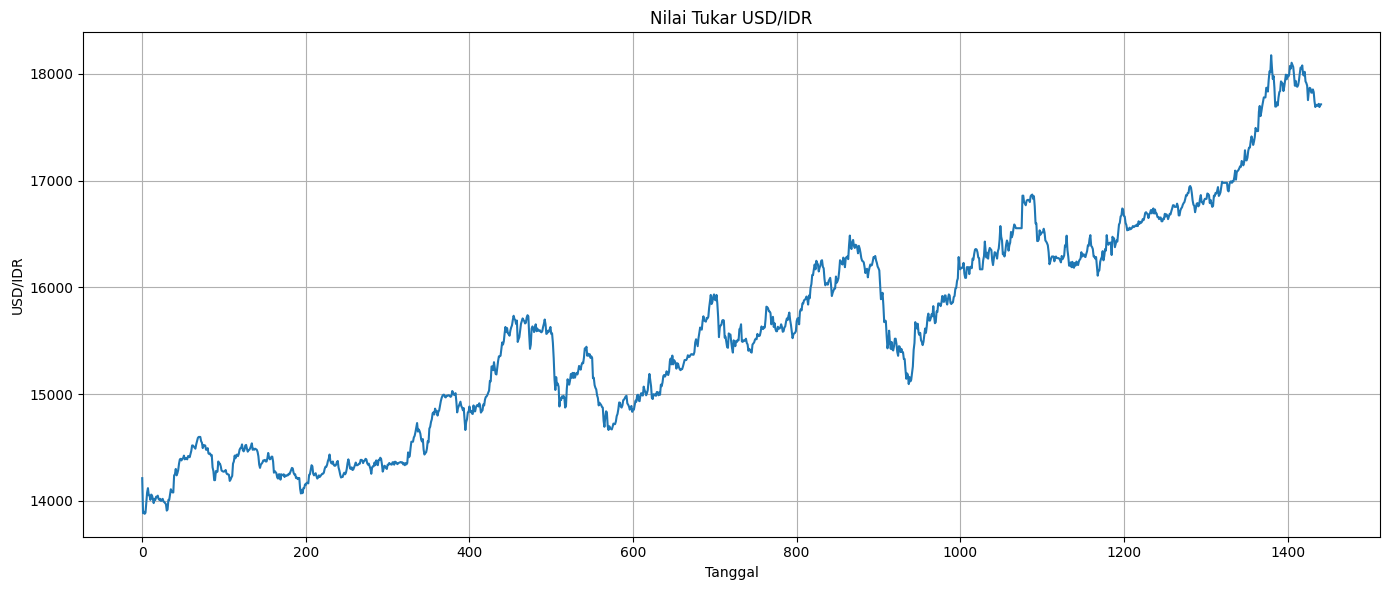

In [70]:
# Plot Data Awal
plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["Terakhir"]
)

plt.title("Nilai Tukar USD/IDR")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")

plt.grid(True)
plt.tight_layout()
plt.show()

#Training dan Testing

In [71]:
n_train = 1400

train = data.iloc[:n_train].copy()
test = data.iloc[n_train:].copy()

print("\n======================================")
print("PEMBAGIAN DATA")
print("======================================")

print("Total observasi  :", len(data))
print("Training         :", len(train))
print("Testing          :", len(test))

print("\nPeriode Training:")
print(train.index.min(), "sampai", train.index.max())

print("\nPeriode Testing:")
print(test.index.min(), "sampai", test.index.max())


PEMBAGIAN DATA
Total observasi  : 1442
Training         : 1400
Testing          : 42

Periode Training:
0 sampai 1399

Periode Testing:
1400 sampai 1441


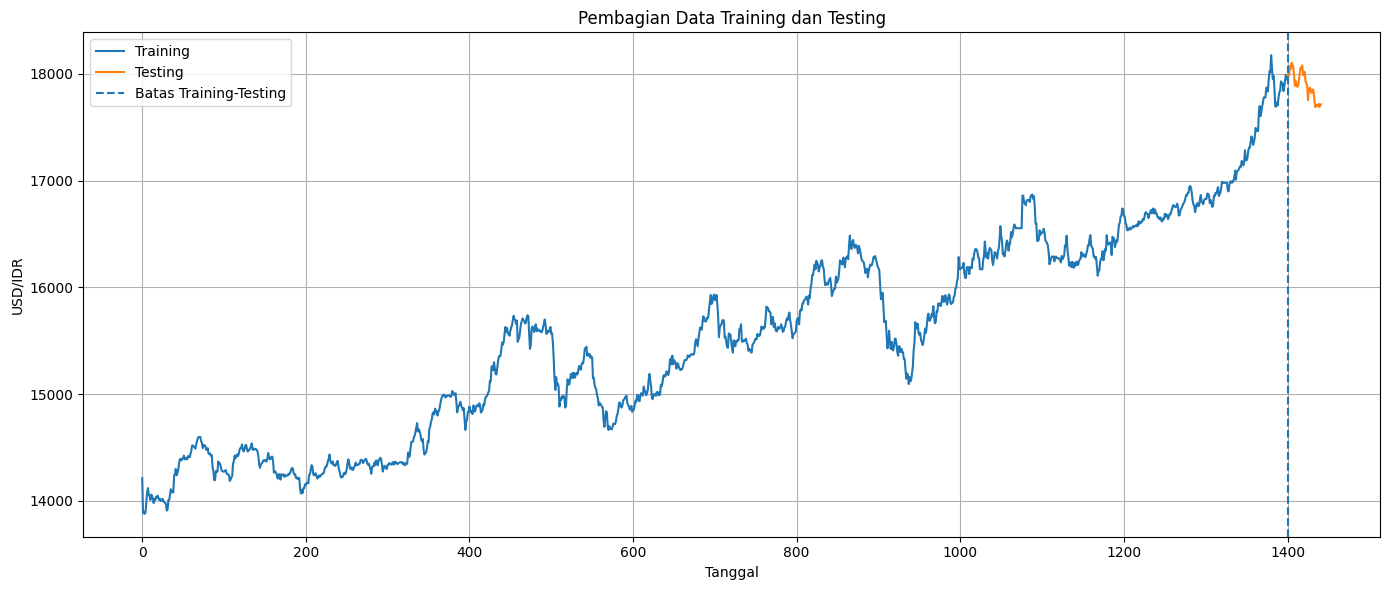

In [72]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train["Terakhir"],
    label="Training"
)

plt.plot(
    test.index,
    test["Terakhir"],
    label="Testing"
)

plt.axvline(
    x=test.index[0],
    linestyle="--",
    label="Batas Training-Testing"
)

plt.title("Pembagian Data Training dan Testing")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()

In [73]:
y_train = train["Terakhir"]
y_test = test["Terakhir"]

## Uji Stasioneritas

In [74]:
def uji_adf(data_series, nama_data):

    hasil = adfuller(data_series.dropna())

    adf_stat = hasil[0]
    p_value = hasil[1]

    print("\n======================================")
    print(f"UJI ADF - {nama_data}")
    print("======================================")
    print(f"ADF Statistic : {adf_stat:.4f}")
    print(f"p-value       : {p_value:.4f}")

    print("\nCritical Value:")

    for key, value in hasil[4].items():
        print(f"{key} : {value:.4f}")

    print("\nKeputusan:")

    if p_value < 0.05:
        print("Tolak H0")
        print("Kesimpulan: Data stasioner dalam rataan.")
    else:
        print("Gagal menolak H0")
        print("Kesimpulan: Data tidak stasioner dalam rataan.")


uji_adf(y_train, "Data Training")


UJI ADF - Data Training
ADF Statistic : -0.0584
p-value       : 0.9534

Critical Value:
1% : -3.4351
5% : -2.8636
10% : -2.5679

Keputusan:
Gagal menolak H0
Kesimpulan: Data tidak stasioner dalam rataan.


/tmp/ipykernel_1504/1325515459.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(data_series.dropna())


## Differencing

In [75]:
y_train_diff = y_train.diff().dropna()

print("Data sebelum differencing :", len(y_train))
print("Data setelah differencing  :", len(y_train_diff))

print("\n5 data pertama setelah differencing:")
print(y_train_diff.head())

Data sebelum differencing : 1400
Data setelah differencing  : 1399

5 data pertama setelah differencing:
1   -328.7
2     15.0
3    -20.0
4     10.0
5     90.0
Name: Terakhir, dtype: float64


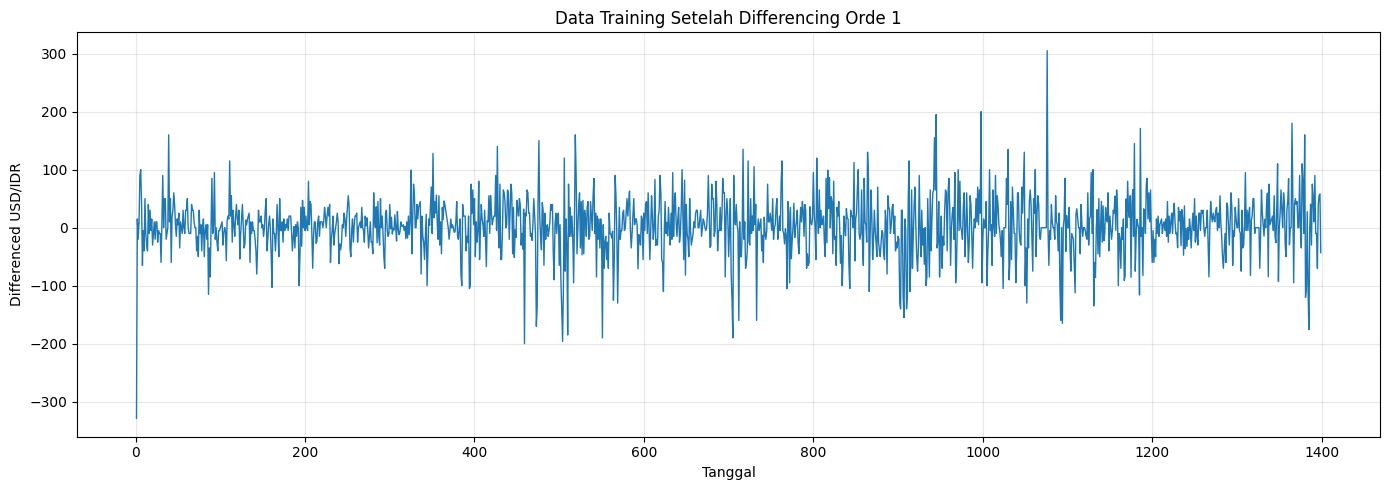

In [76]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_train_diff.index,
    y_train_diff,
    linewidth=1
)

plt.title("Data Training Setelah Differencing Orde 1")
plt.xlabel("Tanggal")
plt.ylabel("Differenced USD/IDR")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Uji stasioneritas

In [77]:
#ADF
stasioner_diff = uji_adf(
    y_train_diff,
    "Data Setelah Differencing"
)


UJI ADF - Data Setelah Differencing
ADF Statistic : -13.4654
p-value       : 0.0000

Critical Value:
1% : -3.4351
5% : -2.8636
10% : -2.5679

Keputusan:
Tolak H0
Kesimpulan: Data stasioner dalam rataan.


/tmp/ipykernel_1504/1325515459.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(data_series.dropna())


HASIL BOX-COX
Lambda optimal : 1.3852
95% CI         : (1.2196, 1.5582)
Shift          : 329.7000


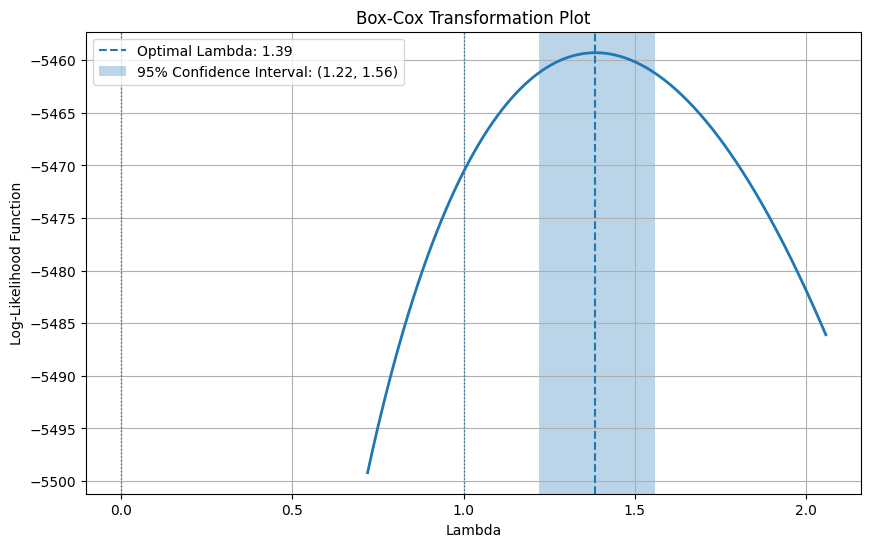

In [78]:
#Stasioneritas dalam Ragam
from scipy.stats import boxcox, boxcox_llf
import numpy as np
import matplotlib.pyplot as plt

# Data setelah differencing
data_diff = y_train_diff.dropna()

# SHIFT DATA JIKA ADA NILAI <= 0
if data_diff.min() <= 0:
    shift = abs(data_diff.min()) + 1
    data_boxcox = data_diff + shift
else:
    shift = 0
    data_boxcox = data_diff.copy()


# MENENTUKAN LAMBDA OPTIMAL DAN 95% CI
_, lambda_fit, ci = boxcox(
    data_boxcox,
    alpha=0.05
)

print("======================================")
print("HASIL BOX-COX")
print("======================================")
print(f"Lambda optimal : {lambda_fit:.4f}")
print(f"95% CI         : ({ci[0]:.4f}, {ci[1]:.4f})")
print(f"Shift          : {shift:.4f}")


# RENTANG LAMBDA UNTUK PLOT
lambdas = np.linspace(
    ci[0] - 0.5,
    ci[1] + 0.5,
    300
)

# Hitung log-likelihood untuk setiap lambda
llf = [
    boxcox_llf(lmbda, data_boxcox)
    for lmbda in lambdas
]


# PLOT BOX-COX
plt.figure(figsize=(10, 6))

plt.plot(
    lambdas,
    llf,
    linewidth=2
)

# Lambda optimal
plt.axvline(
    lambda_fit,
    linestyle='--',
    linewidth=1.5,
    label=f'Optimal Lambda: {lambda_fit:.2f}'
)

# Confidence interval 95%
plt.axvspan(
    ci[0],
    ci[1],
    alpha=0.3,
    label=f'95% Confidence Interval: ({ci[0]:.2f}, {ci[1]:.2f})'
)

# Lambda = 0 dan 1 sebagai referensi
plt.axvline(
    0,
    linestyle=':',
    linewidth=1
)

plt.axvline(
    1,
    linestyle=':',
    linewidth=1
)

plt.xlabel('Lambda')
plt.ylabel('Log-Likelihood Function')
plt.title('Box-Cox Transformation Plot')
plt.legend()
plt.grid(True)

plt.show()

## Transformasi

In [79]:
# TRANSFORMASI BOX-COX
from scipy.stats import boxcox

# Transformasi menggunakan lambda optimal
y_train_boxcox = boxcox(
    data_boxcox,
    lmbda=lambda_fit
)

# Jadikan Series agar index tetap sama
y_train_boxcox = pd.Series(
    y_train_boxcox,
    index=y_train_diff.index
)

print("======================================")
print("TRANSFORMASI BOX-COX")
print("======================================")
print(f"Lambda yang digunakan : {lambda_fit:.4f}")
print(f"Shift yang digunakan  : {shift:.4f}")

print("\n5 data pertama setelah transformasi:")
print(y_train_boxcox.head())

TRANSFORMASI BOX-COX
Lambda yang digunakan : 1.3852
Shift yang digunakan  : 329.7000

5 data pertama setelah transformasi:
1       0.000000
2    2361.131230
3    2035.584066
4    2313.809377
5    3101.554617
dtype: float64


In [80]:
print(data.columns)

Index(['Tanggal', 'Terakhir'], dtype='object')


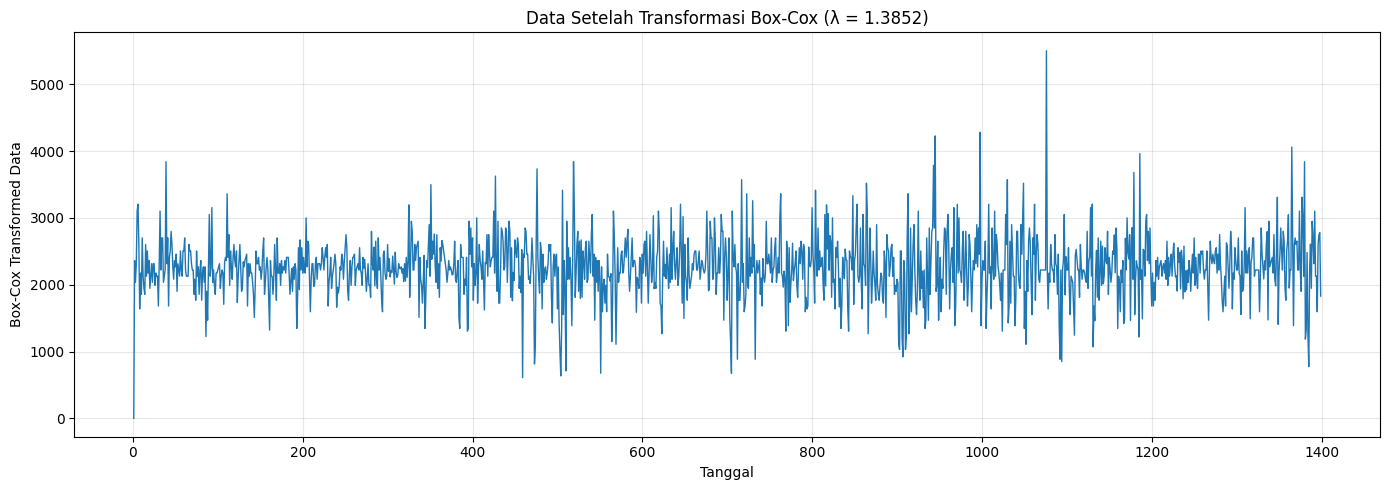

In [81]:
# ============================================
# PLOT SETELAH TRANSFORMASI BOX-COX
# ============================================

plt.figure(figsize=(14, 5))

plt.plot(
    y_train_boxcox.index,
    y_train_boxcox,
    linewidth=1
)

plt.title(
    f"Data Setelah Transformasi Box-Cox (λ = {lambda_fit:.4f})"
)

plt.xlabel("Tanggal")
plt.ylabel("Box-Cox Transformed Data")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Stasioneritas

In [82]:
# Stasioneritas dalam Rataan
from statsmodels.tsa.stattools import adfuller

def uji_adf(data_series, nama_data):
    hasil = adfuller(data_series.dropna())

    adf_stat = hasil[0]
    p_value = hasil[1]

    print("\n======================================")
    print(f"UJI ADF - {nama_data}")
    print("======================================")
    print(f"ADF Statistic : {adf_stat:.4f}")
    print(f"p-value       : {p_value:.4f}")

    print("\nCritical Value:")
    for key, value in hasil[4].items():
        print(f"{key} : {value:.4f}")

    if p_value < 0.05:
        print("\nKeputusan : Tolak H0")
        print("Kesimpulan: Data stasioner dalam rataan.")
        return True
    else:
        print("\nKeputusan : Gagal menolak H0")
        print("Kesimpulan: Data tidak stasioner dalam rataan.")
        return False


# ADF setelah transformasi Box-Cox
stasioner_boxcox = uji_adf(
    y_train_boxcox,
    "Data Setelah Transformasi Box-Cox"
)


UJI ADF - Data Setelah Transformasi Box-Cox
ADF Statistic : -13.5721
p-value       : 0.0000

Critical Value:
1% : -3.4351
5% : -2.8636
10% : -2.5679

Keputusan : Tolak H0
Kesimpulan: Data stasioner dalam rataan.


/tmp/ipykernel_1504/1837552599.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(data_series.dropna())


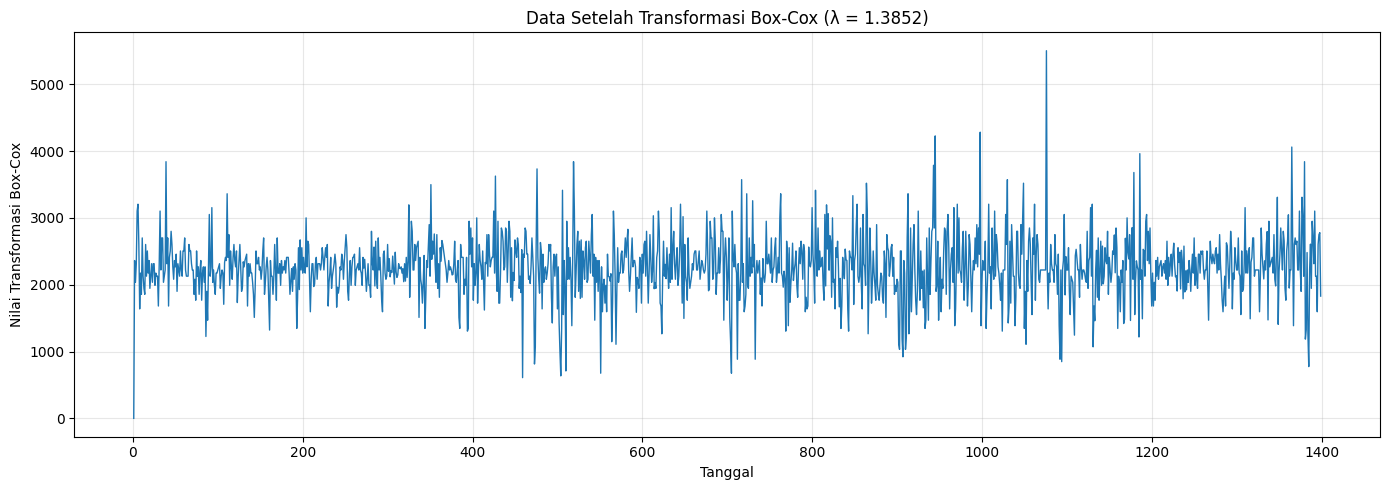

In [83]:
# Stasioneritas dalam Ragam
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    y_train_boxcox.index,
    y_train_boxcox,
    linewidth=1
)

plt.title(
    f"Data Setelah Transformasi Box-Cox (λ = {lambda_fit:.4f})"
)

plt.xlabel("Tanggal")
plt.ylabel("Nilai Transformasi Box-Cox")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [84]:
from statsmodels.stats.diagnostic import het_arch

arch_test = het_arch(
    y_train_boxcox.dropna(),
    nlags=10
)

print("======================================")
print("UJI ARCH-LM")
print("======================================")
print(f"LM Statistic : {arch_test[0]:.4f}")
print(f"LM p-value   : {arch_test[1]:.4f}")
print(f"F Statistic  : {arch_test[2]:.4f}")
print(f"F p-value    : {arch_test[3]:.4f}")

if arch_test[1] < 0.05:
    print("\nKeputusan : Tolak H0")
    print("Kesimpulan: Terdapat efek ARCH / ragam belum konstan.")
else:
    print("\nKeputusan : Gagal menolak H0")
    print("Kesimpulan: Tidak terdapat bukti efek ARCH yang signifikan.")

UJI ARCH-LM
LM Statistic : 12.3342
LM p-value   : 0.2633
F Statistic  : 1.2346
F p-value    : 0.2638

Keputusan : Gagal menolak H0
Kesimpulan: Tidak terdapat bukti efek ARCH yang signifikan.


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


## ACF & PACF

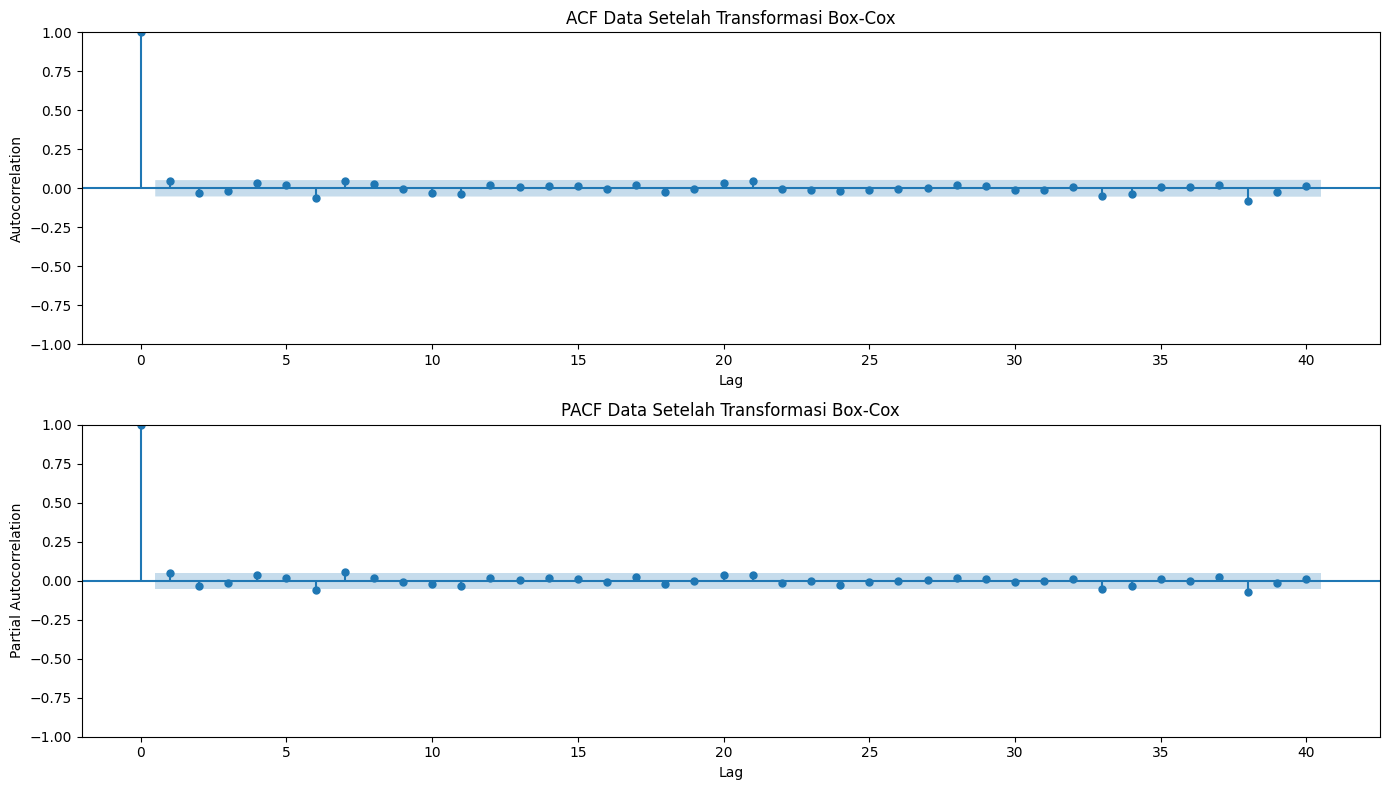

In [85]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(
    y_train_boxcox,
    lags=40,
    ax=axes[0]
)
axes[0].set_title("ACF Data Setelah Transformasi Box-Cox")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")

plot_pacf(
    y_train_boxcox,
    lags=40,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF Data Setelah Transformasi Box-Cox")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

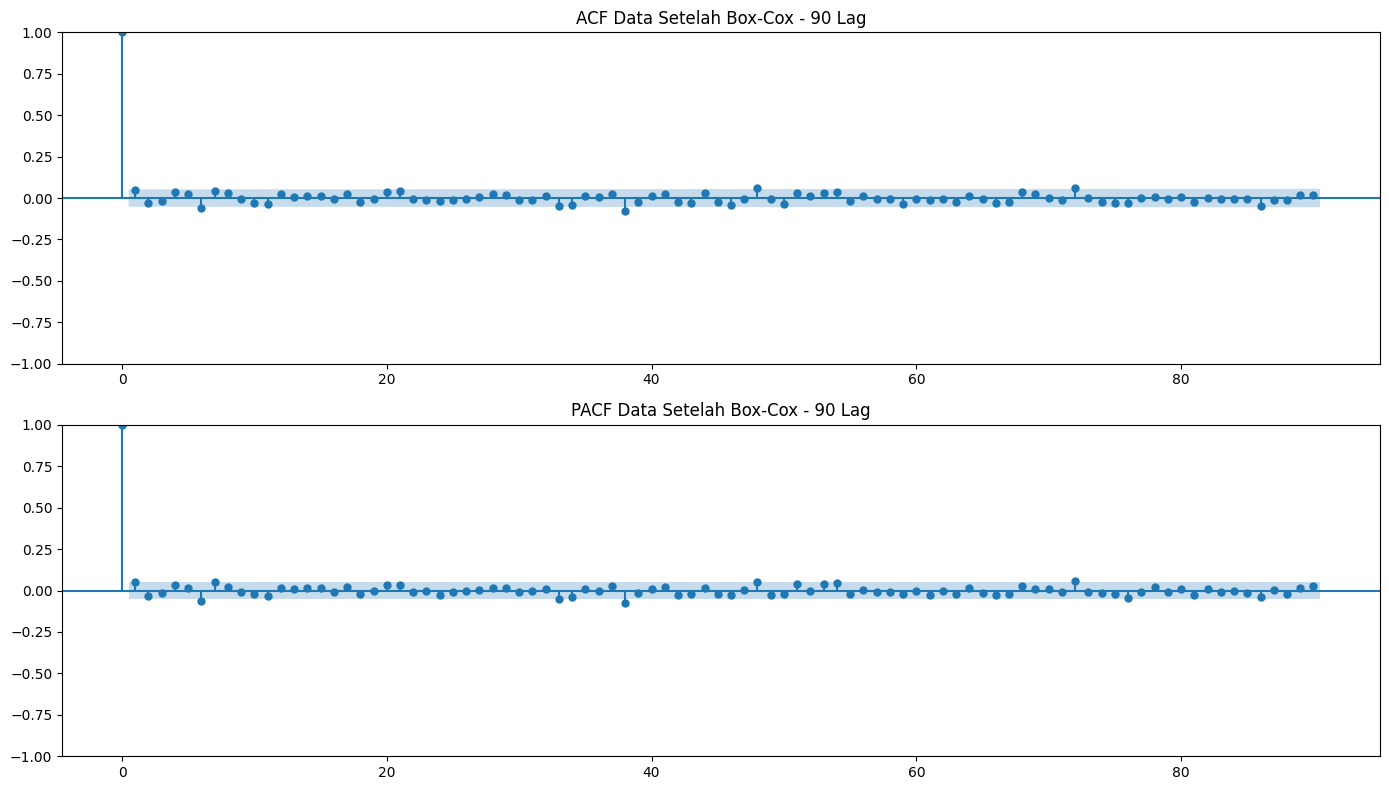

In [86]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

plot_acf(
    y_train_boxcox,
    lags=90,
    ax=axes[0]
)
axes[0].set_title("ACF Data Setelah Box-Cox - 90 Lag")

plot_pacf(
    y_train_boxcox,
    lags=90,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF Data Setelah Box-Cox - 90 Lag")

plt.tight_layout()
plt.show()

## GARCH

In [87]:
!pip install arch -q

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from arch import arch_model

In [89]:
y_garch = y_train_boxcox.dropna().copy()

In [90]:
print("Jumlah observasi:", len(y_garch))
print(y_garch.head())

Jumlah observasi: 1399
1       0.000000
2    2361.131230
3    2035.584066
4    2313.809377
5    3101.554617
dtype: float64


In [91]:
model_garch = arch_model(
    y_garch,
    mean='ARX',
    lags=1,
    vol='GARCH',
    p=1,
    q=1,
    dist='normal'
)

hasil_garch = model_garch.fit(disp='off')

print(hasil_garch.summary())

                           AR - GARCH Model Results                           
Dep. Variable:                   None   R-squared:                       0.002
Mean Model:                        AR   Adj. R-squared:                  0.002
Vol Model:                      GARCH   Log-Likelihood:               -10492.6
Distribution:                  Normal   AIC:                           20995.3
Method:            Maximum Likelihood   BIC:                           21021.5
                                        No. Observations:                 1398
Date:                Wed, Oct 14 2026   Df Residuals:                     1396
Time:                        01:05:00   Df Model:                            2
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
Const       2131.4845     66.064     32.264 2.256e-228 [2.

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.082e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [92]:
print("======================================")
print("PARAMETER MODEL AR(1)-GARCH(1,1)")
print("======================================")

print(hasil_garch.params)

print("\nP-VALUE:")
print(hasil_garch.pvalues)

PARAMETER MODEL AR(1)-GARCH(1,1)
Const       2131.484540
None[1]        0.056402
omega       4154.654101
alpha[1]       0.043645
beta[1]        0.937867
Name: params, dtype: float64

P-VALUE:
Const       2.256111e-228
None[1]      4.756054e-02
omega        8.681566e-01
alpha[1]     5.832571e-01
beta[1]      1.386650e-06
Name: pvalues, dtype: float64


In [93]:
alpha = hasil_garch.params["alpha[1]"]
beta = hasil_garch.params["beta[1]"]

print("======================================")
print("PERSISTENSI VOLATILITAS")
print("======================================")
print(f"Alpha (α1) : {alpha:.6f}")
print(f"Beta (β1)  : {beta:.6f}")
print(f"Alpha + Beta : {alpha + beta:.6f}")

PERSISTENSI VOLATILITAS
Alpha (α1) : 0.043645
Beta (β1)  : 0.937867
Alpha + Beta : 0.981512


In [94]:
std_resid = hasil_garch.std_resid.dropna()

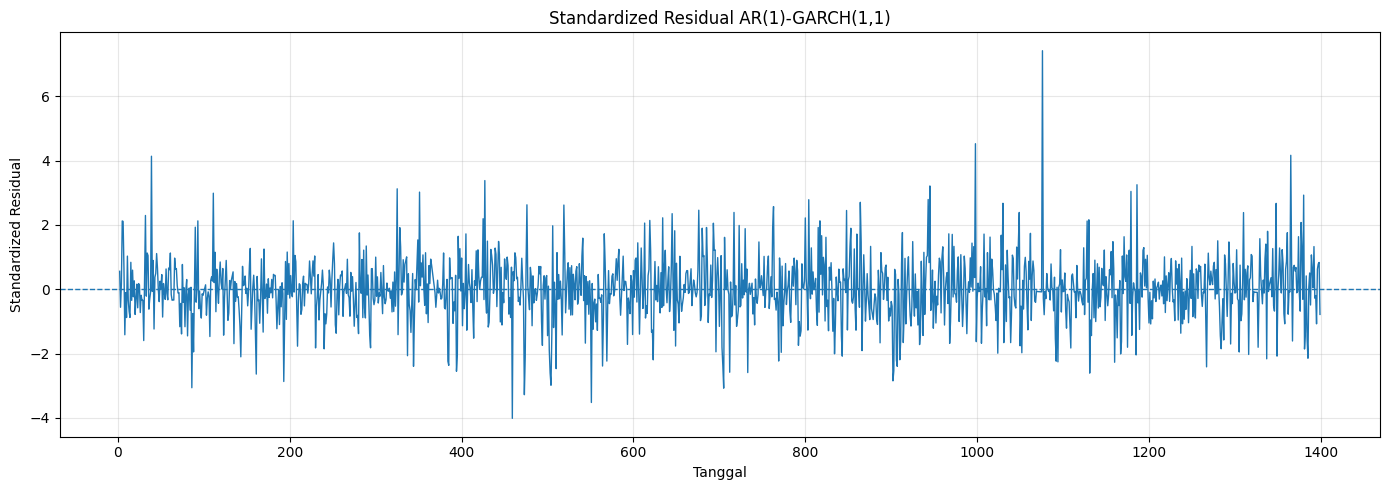

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    std_resid.index,
    std_resid,
    linewidth=1
)

plt.axhline(0, linestyle='--', linewidth=1)

plt.title("Standardized Residual AR(1)-GARCH(1,1)")
plt.xlabel("Tanggal")
plt.ylabel("Standardized Residual")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## UJI Ljung-Box Residual

In [96]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_resid = acorr_ljungbox(
    std_resid,
    lags=[10, 20],
    return_df=True
)

print("======================================")
print("UJI LJUNG-BOX STANDARDIZED RESIDUAL")
print("======================================")
print(ljung_resid)

UJI LJUNG-BOX STANDARDIZED RESIDUAL
      lb_stat  lb_pvalue
10  15.413233   0.117707
20  21.046587   0.394395


In [97]:
ljung_squared = acorr_ljungbox(
    std_resid**2,
    lags=[10, 20],
    return_df=True
)

print("======================================")
print("UJI LJUNG-BOX KUADRAT STANDARDIZED RESIDUAL")
print("======================================")
print(ljung_squared)

UJI LJUNG-BOX KUADRAT STANDARDIZED RESIDUAL
     lb_stat  lb_pvalue
10  5.261357   0.873049
20  7.734173   0.993485


In [98]:
from statsmodels.stats.diagnostic import het_arch

arch_after = het_arch(
    std_resid,
    nlags=10
)

print("======================================")
print("UJI ARCH-LM SETELAH GARCH(1,1)")
print("======================================")
print(f"LM Statistic : {arch_after[0]:.4f}")
print(f"LM p-value   : {arch_after[1]:.4f}")
print(f"F Statistic  : {arch_after[2]:.4f}")
print(f"F p-value    : {arch_after[3]:.4f}")

UJI ARCH-LM SETELAH GARCH(1,1)
LM Statistic : 5.1997
LM p-value   : 0.8774
F Statistic  : 0.5178
F p-value    : 0.8786


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [99]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box residual
lb_resid = acorr_ljungbox(
    std_resid,
    lags=10,
    return_df=True
)

print("======================================")
print("UJI LJUNG-BOX RESIDUAL TERSTANDARISASI")
print("======================================")
print(lb_resid)

# Ljung-Box residual kuadrat
lb_resid_sq = acorr_ljungbox(
    std_resid**2,
    lags=10,
    return_df=True
)

print("\n======================================")
print("UJI LJUNG-BOX RESIDUAL TERSTANDARISASI KUADRAT")
print("======================================")
print(lb_resid_sq)

UJI LJUNG-BOX RESIDUAL TERSTANDARISASI
      lb_stat  lb_pvalue
1    0.186031   0.666240
2    0.813587   0.665782
3    1.271471   0.735918
4    4.188098   0.381148
5    6.391737   0.269945
6   11.866283   0.065019
7   13.291946   0.065307
8   15.148582   0.056320
9   15.150616   0.086881
10  15.413233   0.117707

UJI LJUNG-BOX RESIDUAL TERSTANDARISASI KUADRAT
     lb_stat  lb_pvalue
1   0.577949   0.447117
2   0.820148   0.663601
3   0.824991   0.843481
4   0.842524   0.932658
5   2.429404   0.787087
6   3.362825   0.762122
7   3.763074   0.806626
8   4.865671   0.771832
9   5.252855   0.811733
10  5.261357   0.873049


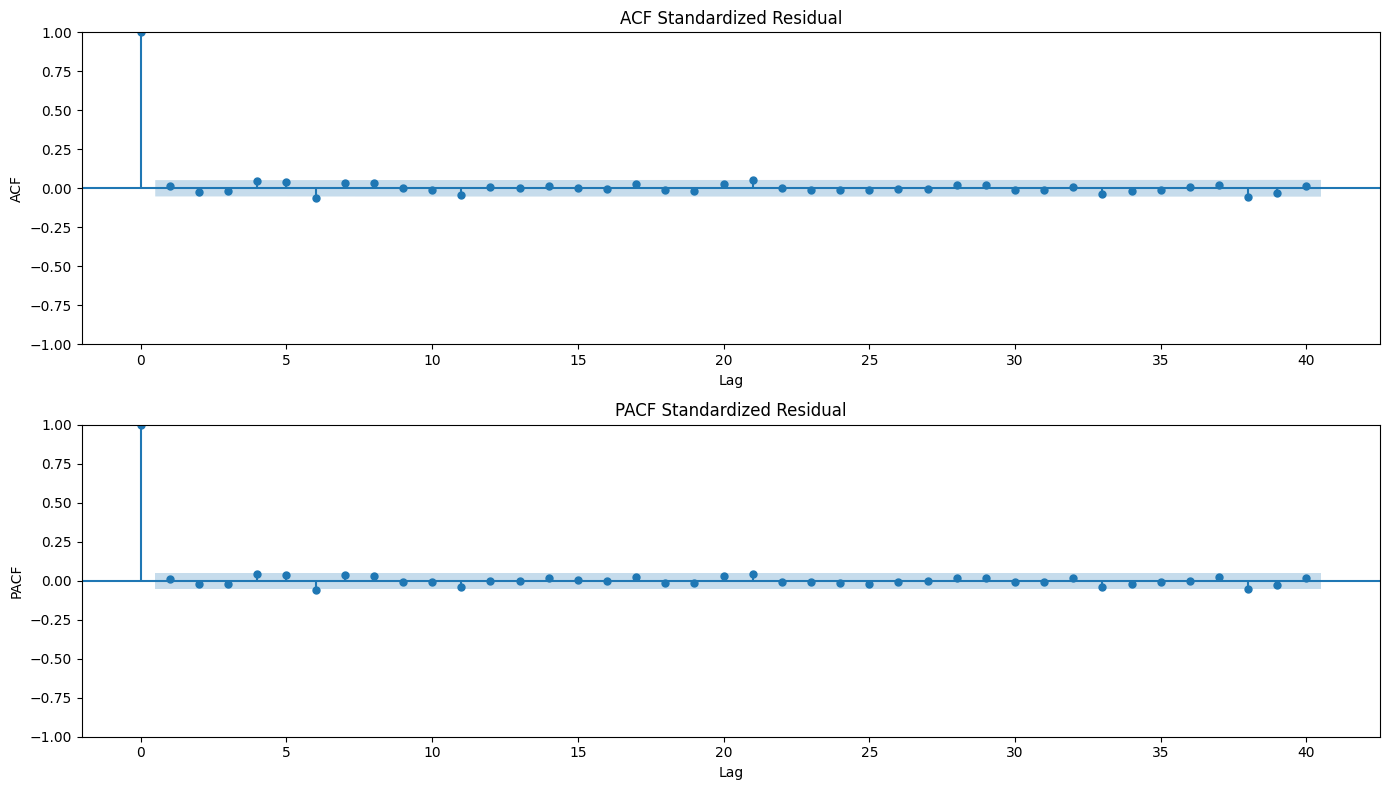

In [100]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# ACF residual terstandarisasi
plot_acf(
    std_resid,
    lags=40,
    ax=axes[0]
)

axes[0].set_title("ACF Standardized Residual")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("ACF")

# PACF residual terstandarisasi
plot_pacf(
    std_resid,
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("PACF Standardized Residual")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

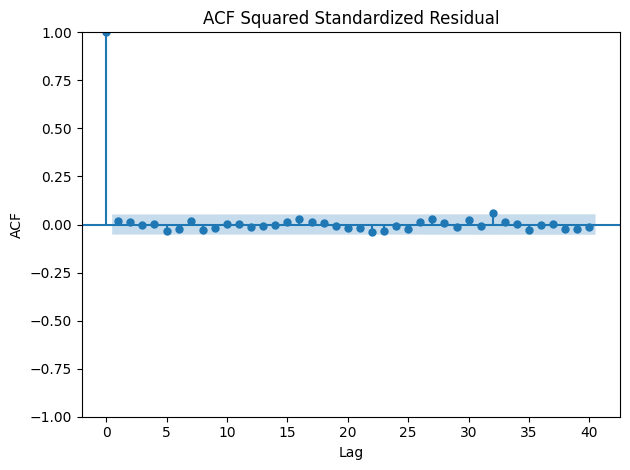

In [101]:
plt.figure(figsize=(14, 5))

plot_acf(
    std_resid**2,
    lags=40
)

plt.title("ACF Squared Standardized Residual")
plt.xlabel("Lag")
plt.ylabel("ACF")
plt.tight_layout()
plt.show()

In [102]:
print(hasil_garch.summary())

                           AR - GARCH Model Results                           
Dep. Variable:                   None   R-squared:                       0.002
Mean Model:                        AR   Adj. R-squared:                  0.002
Vol Model:                      GARCH   Log-Likelihood:               -10492.6
Distribution:                  Normal   AIC:                           20995.3
Method:            Maximum Likelihood   BIC:                           21021.5
                                        No. Observations:                 1398
Date:                Wed, Oct 14 2026   Df Residuals:                     1396
Time:                        01:05:00   Df Model:                            2
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
Const       2131.4845     66.064     32.264 2.256e-228 [2.

In [103]:
# Parameter GARCH
alpha = hasil_garch.params["alpha[1]"]
beta = hasil_garch.params["beta[1]"]

print("======================================")
print("PARAMETER GARCH(1,1)")
print("======================================")
print(f"Alpha (α1) : {alpha:.4f}")
print(f"Beta  (β1) : {beta:.4f}")
print(f"α1 + β1    : {alpha + beta:.4f}")

PARAMETER GARCH(1,1)
Alpha (α1) : 0.0436
Beta  (β1) : 0.9379
α1 + β1    : 0.9815


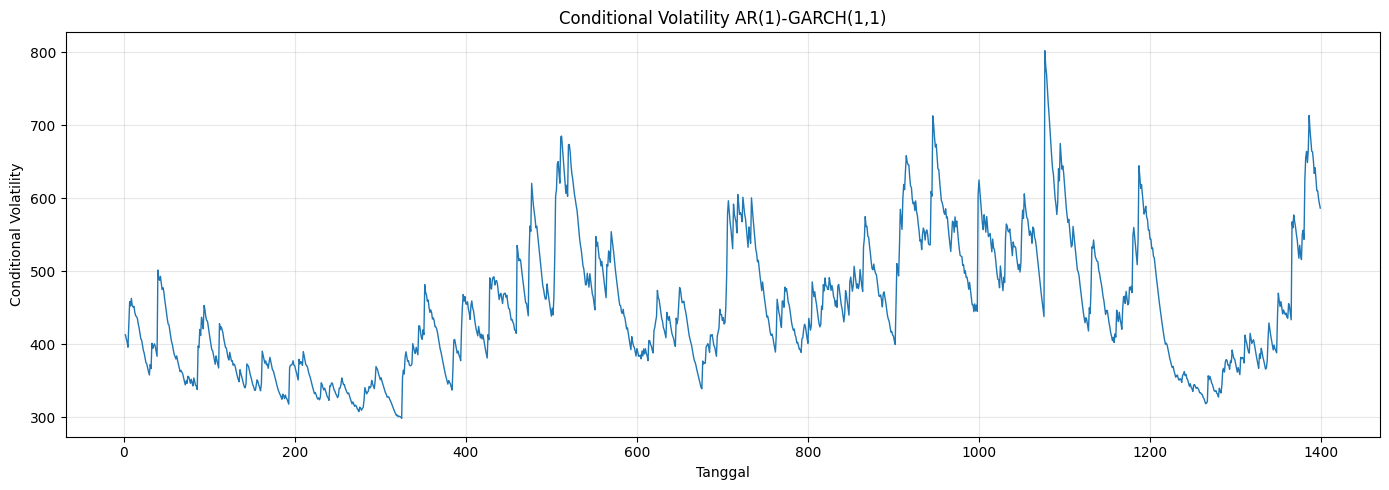

In [104]:
# Plot Conditional Volatility
plt.figure(figsize=(14, 5))

plt.plot(
    hasil_garch.conditional_volatility,
    linewidth=1
)

plt.title("Conditional Volatility AR(1)-GARCH(1,1)")
plt.xlabel("Tanggal")
plt.ylabel("Conditional Volatility")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

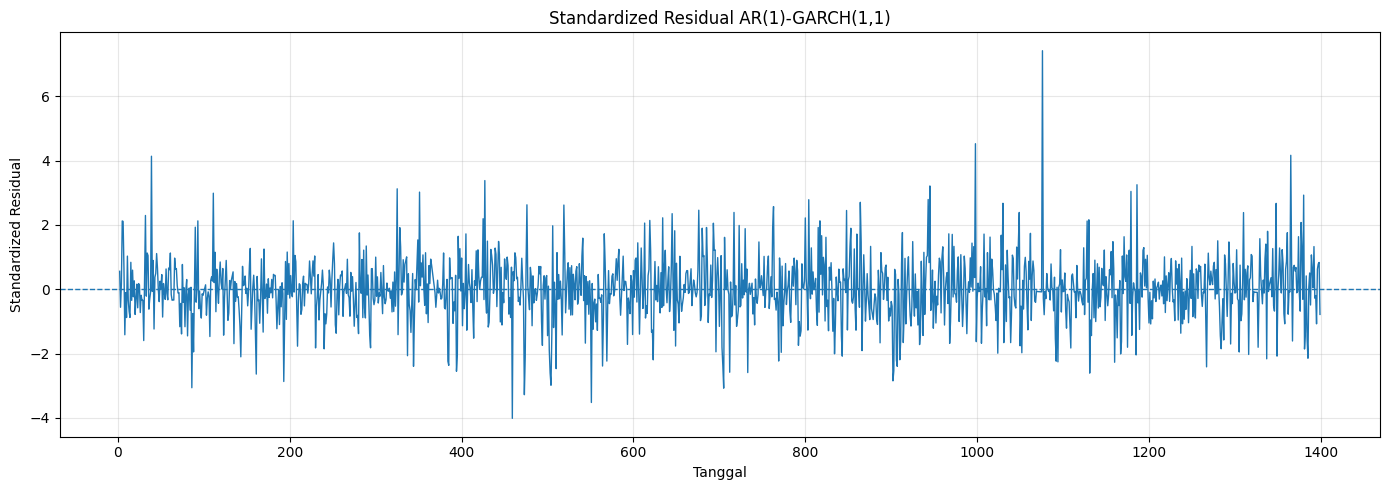

In [105]:
# Plot Standardized Residual
plt.figure(figsize=(14, 5))

plt.plot(
    std_resid,
    linewidth=1
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title("Standardized Residual AR(1)-GARCH(1,1)")
plt.xlabel("Tanggal")
plt.ylabel("Standardized Residual")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [106]:
dist='normal'

In [107]:
from scipy.stats import jarque_bera

jb_test = jarque_bera(std_resid)

print("======================================")
print("UJI NORMALITAS JARQUE-BERA")
print("======================================")
print(f"JB Statistic : {jb_test.statistic:.4f}")
print(f"p-value      : {jb_test.pvalue:.4f}")

UJI NORMALITAS JARQUE-BERA
JB Statistic : 751.6021
p-value      : 0.0000


## Signifikansi Parameter

In [108]:
print("======================================")
print("PARAMETER MODEL AR(1)-GARCH(1,1)")
print("======================================")
print(hasil_garch.params)

print("\n======================================")
print("P-VALUE PARAMETER")
print("======================================")
print(hasil_garch.pvalues)

PARAMETER MODEL AR(1)-GARCH(1,1)
Const       2131.484540
None[1]        0.056402
omega       4154.654101
alpha[1]       0.043645
beta[1]        0.937867
Name: params, dtype: float64

P-VALUE PARAMETER
Const       2.256111e-228
None[1]      4.756054e-02
omega        8.681566e-01
alpha[1]     5.832571e-01
beta[1]      1.386650e-06
Name: pvalues, dtype: float64


In [109]:
omega = hasil_garch.params["omega"]
alpha = hasil_garch.params["alpha[1]"]
beta = hasil_garch.params["beta[1]"]

print("======================================")
print("PEMERIKSAAN PARAMETER GARCH(1,1)")
print("======================================")
print(f"Omega (ω)  : {omega:.6f}")
print(f"Alpha (α₁) : {alpha:.6f}")
print(f"Beta (β₁)  : {beta:.6f}")
print(f"α₁ + β₁    : {alpha + beta:.6f}")

PEMERIKSAAN PARAMETER GARCH(1,1)
Omega (ω)  : 4154.654101
Alpha (α₁) : 0.043645
Beta (β₁)  : 0.937867
α₁ + β₁    : 0.981512


## Forecasting Data Testing

In [110]:
y_all = pd.concat([y_train, y_test])

In [111]:
# ======================================
# ROLLING ONE-STEP-AHEAD FORECAST
# ======================================

forecast_diff = []
forecast_level = []

# Gabungkan data aktual
y_all = pd.concat([y_train, y_test])

# Differencing seluruh data
y_all_diff = y_all.diff().dropna()

# Shift untuk Box-Cox
y_all_shift = y_all_diff + shift

# Transformasi Box-Cox
y_all_boxcox = boxcox(
    y_all_shift,
    lmbda=lambda_fit
)

y_all_boxcox = pd.Series(
    y_all_boxcox,
    index=y_all_diff.index
)

# Rolling forecast
for i in range(len(y_test)):

    # Data yang tersedia sampai sebelum observasi
    # yang akan diramalkan
    end_idx = len(y_train_boxcox) + i

    data_roll = y_all_boxcox.iloc[:end_idx]

    # Model AR(1)-GARCH(1,1)
    model_roll = arch_model(
        data_roll,
        mean='ARX',
        lags=1,
        vol='GARCH',
        p=1,
        q=1,
        dist='normal'
    )

    hasil_roll = model_roll.fit(disp='off')

    # Forecast 1 langkah ke depan
    forecast_roll = hasil_roll.forecast(
        horizon=1,
        reindex=False
    )

    forecast_boxcox = forecast_roll.mean.iloc[-1, 0]

    # Kembalikan Box-Cox
    if lambda_fit != 0:
        forecast_shift = (
            lambda_fit * forecast_boxcox + 1
        ) ** (1 / lambda_fit)
    else:
        forecast_shift = np.exp(forecast_boxcox)

    # Hilangkan shift
    forecast_d = forecast_shift - shift

    forecast_diff.append(forecast_d)

    # ==================================
    # INVERSE DIFFERENCING
    # GUNAKAN NILAI AKTUAL SEBELUMNYA
    # ==================================

    if i == 0:
        previous_actual = y_train.iloc[-1]
    else:
        previous_actual = y_test.iloc[i - 1]

    forecast_y = previous_actual + forecast_d

    forecast_level.append(forecast_y)


forecast_level = pd.Series(
    forecast_level,
    index=y_test.index
)

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.082e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.081e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base

In [112]:
# Tabel Hasil Forecasting
tabel_forecast = pd.DataFrame({
    "Tanggal": y_test.index,
    "Aktual": y_test.values,
    "Forecast": forecast_level.values
})

print("======================================")
print("TABEL HASIL FORECASTING")
print("======================================")

display(tabel_forecast.head(20))

TABEL HASIL FORECASTING


,Tanggal,Aktual,Forecast
0,1400,17990.0,17951.572231
1,1401,17975.0,17996.015926
2,1402,17994.0,17978.115743
3,1403,18075.0,17998.841439
4,1404,18050.0,18083.672982
5,1405,18105.0,18052.620981
6,1406,18085.0,18112.087989
7,1407,18065.0,18087.921328
8,1408,17985.0,18067.910993
9,1409,17890.0,17984.792953


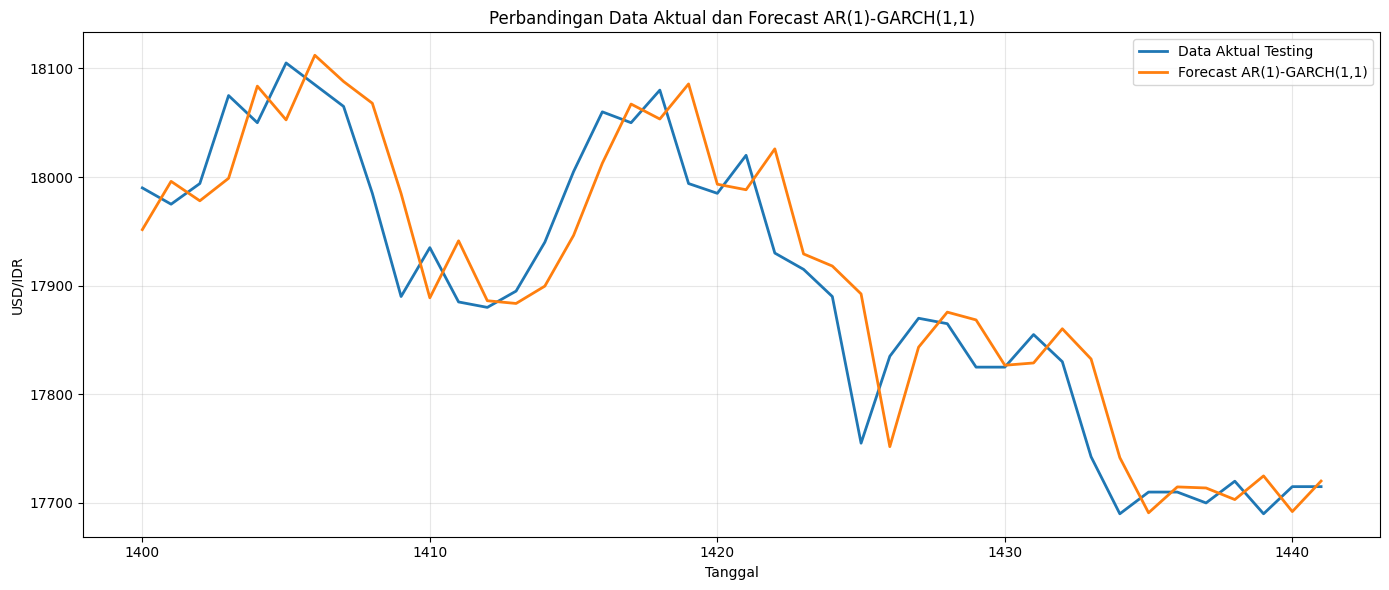

In [113]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Data Aktual Testing",
    linewidth=2
)

plt.plot(
    forecast_level.index,
    forecast_level,
    label="Forecast AR(1)-GARCH(1,1)",
    linewidth=2
)

plt.title("Perbandingan Data Aktual dan Forecast AR(1)-GARCH(1,1)")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [114]:
# ======================================
# TABEL HASIL FORECASTING DATA TESTING
# ======================================

tabel_forecast = pd.DataFrame({
    "Tanggal": y_test.index,
    "Aktual": y_test.values,
    "Forecast": forecast_level.values
})

# Error
tabel_forecast["Error"] = (
    tabel_forecast["Aktual"] -
    tabel_forecast["Forecast"]
)

# Absolute Error
tabel_forecast["Absolute Error"] = (
    tabel_forecast["Error"].abs()
)

# Absolute Percentage Error
tabel_forecast["APE (%)"] = (
    np.abs(
        (tabel_forecast["Aktual"] -
         tabel_forecast["Forecast"])
        / tabel_forecast["Aktual"]
    ) * 100
)

print("======================================")
print("TABEL HASIL FORECASTING")
print("======================================")

display(tabel_forecast.head(20))

TABEL HASIL FORECASTING


,Tanggal,Aktual,Forecast,Error,Absolute Error,APE (%)
0,1400,17990.0,17951.572231,38.427769,38.427769,0.213606
1,1401,17975.0,17996.015926,-21.015926,21.015926,0.116918
2,1402,17994.0,17978.115743,15.884257,15.884257,0.088275
3,1403,18075.0,17998.841439,76.158561,76.158561,0.421347
4,1404,18050.0,18083.672982,-33.672982,33.672982,0.186554
5,1405,18105.0,18052.620981,52.379019,52.379019,0.289307
6,1406,18085.0,18112.087989,-27.087989,27.087989,0.149782
7,1407,18065.0,18087.921328,-22.921328,22.921328,0.126883
8,1408,17985.0,18067.910993,-82.910993,82.910993,0.461001
9,1409,17890.0,17984.792953,-94.792953,94.792953,0.529866


## Evaluasi Akurasi Forecast

In [115]:
# ======================================
# EVALUASI AKURASI FORECAST
# ======================================

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

# MSE
mse = mean_squared_error(
    y_test,
    forecast_level
)

# RMSE
rmse = np.sqrt(mse)

# MAE
mae = mean_absolute_error(
    y_test,
    forecast_level
)

# MAPE
mape = np.mean(
    np.abs(
        (y_test - forecast_level) /
        y_test
    )
) * 100

print("======================================")
print("EVALUASI FORECAST AR(1)-GARCH(1,1)")
print("======================================")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"MAPE : {mape:.4f}%")

EVALUASI FORECAST AR(1)-GARCH(1,1)
MSE  : 2522.9383
RMSE : 50.2289
MAE  : 39.6245
MAPE : 0.2213%


In [116]:
# ======================================
# TABEL RINGKASAN EVALUASI
# ======================================

evaluasi = pd.DataFrame({
    "Metrik": ["MSE", "RMSE", "MAE", "MAPE"],
    "Nilai": [mse, rmse, mae, mape]
})

print("======================================")
print("RINGKASAN HASIL EVALUASI")
print("======================================")

display(evaluasi)

RINGKASAN HASIL EVALUASI


,Metrik,Nilai
0,MSE,2522.938312
1,RMSE,50.228859
2,MAE,39.624466
3,MAPE,0.221312


## Forecast Data Historis

In [117]:
# ======================================
# DATA HISTORIS
# ======================================

y_historis = data["Terakhir"].copy()

print("Jumlah data historis :", len(y_historis))
print("Periode historis     :", y_historis.index.min(),
      "sampai", y_historis.index.max())

Jumlah data historis : 1442
Periode historis     : 0 sampai 1441


In [134]:
# ======================================
# DATA HISTORIS DENGAN PENAMBAHAN KOLOM TANGGAL
# ======================================

# Mengubah kolom tanggal menjadi format datetime
data["Tanggal"] = pd.to_datetime(
    data["Tanggal"], dayfirst=True
)

# Mengurutkan data berdasarkan tanggal
data = data.sort_values("Tanggal")

# Menjadikan tanggal sebagai indeks
data = data.set_index("Tanggal")

# Mengambil data harga historis
y_historis = data["Terakhir"].copy()

print("Jumlah data historis :", len(y_historis))
print("Periode historis     :", y_historis.index.min(),
      "sampai", y_historis.index.max())
print("Tipe indeks          :", type(y_historis.index))

Jumlah data historis : 1442
Periode historis     : 2021-01-01 00:00:00 sampai 2026-09-01 00:00:00
Tipe indeks          : <class 'pandas.core.indexes.datetimes.DatetimeIndex'>


In [135]:
y_historis

,Terakhir
Tanggal,
2021-01-01,14213.7
2021-01-04,13885.0
2021-01-05,13900.0
2021-01-06,13880.0
2021-01-07,13890.0
...,...
2026-08-26,17700.0
2026-08-27,17720.0
2026-08-28,17690.0


In [136]:
# ======================================
# DIFFERENCING DATA HISTORIS
# ======================================

y_historis_diff = y_historis.diff().dropna()

In [137]:
# ======================================
# SHIFT
# ======================================

y_historis_shift = y_historis_diff + shift

In [138]:
# ======================================
# BOX-COX TRANSFORMATION
# ======================================

y_historis_boxcox = boxcox(
    y_historis_shift,
    lmbda=lambda_fit
)

y_historis_boxcox = pd.Series(
    y_historis_boxcox,
    index=y_historis_diff.index
)

In [139]:
lambda_fit

np.float64(1.3851558041847958)

In [140]:
# ======================================
# AR(1)-GARCH(1,1) DATA HISTORIS
# ======================================

model_historis = arch_model(
    y_historis_boxcox,
    mean='ARX',
    lags=1,
    vol='GARCH',
    p=1,
    q=1,
    dist='normal'
)

hasil_historis = model_historis.fit(
    disp='off'
)

print(hasil_historis.summary())

                           AR - GARCH Model Results                           
Dep. Variable:                   None   R-squared:                       0.002
Mean Model:                        AR   Adj. R-squared:                  0.002
Vol Model:                      GARCH   Log-Likelihood:               -10810.1
Distribution:                  Normal   AIC:                           21630.3
Method:            Maximum Likelihood   BIC:                           21656.7
                                        No. Observations:                 1440
Date:                Wed, Oct 14 2026   Df Residuals:                     1438
Time:                        01:17:09   Df Model:                            2
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
Const       2132.1555     65.003     32.801 5.761e-236 [2.

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.082e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [141]:
# ======================================
# JUMLAH PERIODE FORECAST
# ======================================

horizon = 30

In [142]:
# ======================================
# FORECAST DATA HISTORIS
# ======================================

forecast_historis = hasil_historis.forecast(
    horizon=horizon,
    reindex=False
)

forecast_boxcox_historis = (
    forecast_historis.mean.iloc[-1].values
)

In [144]:
# ======================================
# INVERSE BOX-COX
# ======================================

if lambda_fit != 0:

    forecast_shift_historis = (
        lambda_fit * forecast_boxcox_historis + 1
    ) ** (1 / lambda_fit)

else:

    forecast_shift_historis = np.exp(
        forecast_boxcox_historis
    )

In [145]:
# ======================================
# MENGEMBALIKAN SHIFT
# ======================================

forecast_diff_historis = (
    forecast_shift_historis - shift
)

In [146]:
last_actual = y_historis.iloc[-1]

In [147]:
# ======================================
# INVERSE DIFFERENCING
# ======================================

forecast_level_historis = []

last_value = last_actual

for forecast_d in forecast_diff_historis:

    next_value = last_value + forecast_d

    forecast_level_historis.append(
        next_value
    )

    last_value = next_value

In [148]:
print(y_historis.index)
print(type(y_historis.index[-1]))

DatetimeIndex(['2021-01-01', '2021-01-04', '2021-01-05', '2021-01-06',
               '2021-01-07', '2021-01-08', '2021-01-11', '2021-01-12',
               '2021-01-13', '2021-01-14',
               ...
               '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-24',
               '2026-08-25', '2026-08-26', '2026-08-27', '2026-08-28',
               '2026-08-31', '2026-09-01'],
              dtype='datetime64[ns]', name='Tanggal', length=1442, freq=None)
<class 'pandas._libs.tslibs.timestamps.Timestamp'>


In [149]:
from pandas.tseries.offsets import BDay

tanggal_forecast = pd.date_range(
    start=y_historis.index[-1] + BDay(1),
    periods=horizon,
    freq="B"
)

In [150]:
# ======================================
# TABEL FORECAST DATA HISTORIS
# ======================================

tabel_forecast_historis = pd.DataFrame({
    "Tanggal": tanggal_forecast,
    "Forecast": forecast_level_historis
})

print("======================================")
print("FORECAST DATA HISTORIS")
print("======================================")

display(tabel_forecast_historis)

FORECAST DATA HISTORIS


,Tanggal,Forecast
0,2026-09-02,17718.743970
1,2026-09-03,17722.694603
2,2026-09-04,17726.656670
3,2026-09-07,17730.619368
4,2026-09-08,17734.582102
5,2026-09-09,17738.544838
6,2026-09-10,17742.507574
7,2026-09-11,17746.470309
8,2026-09-14,17750.433045
9,2026-09-15,17754.395781


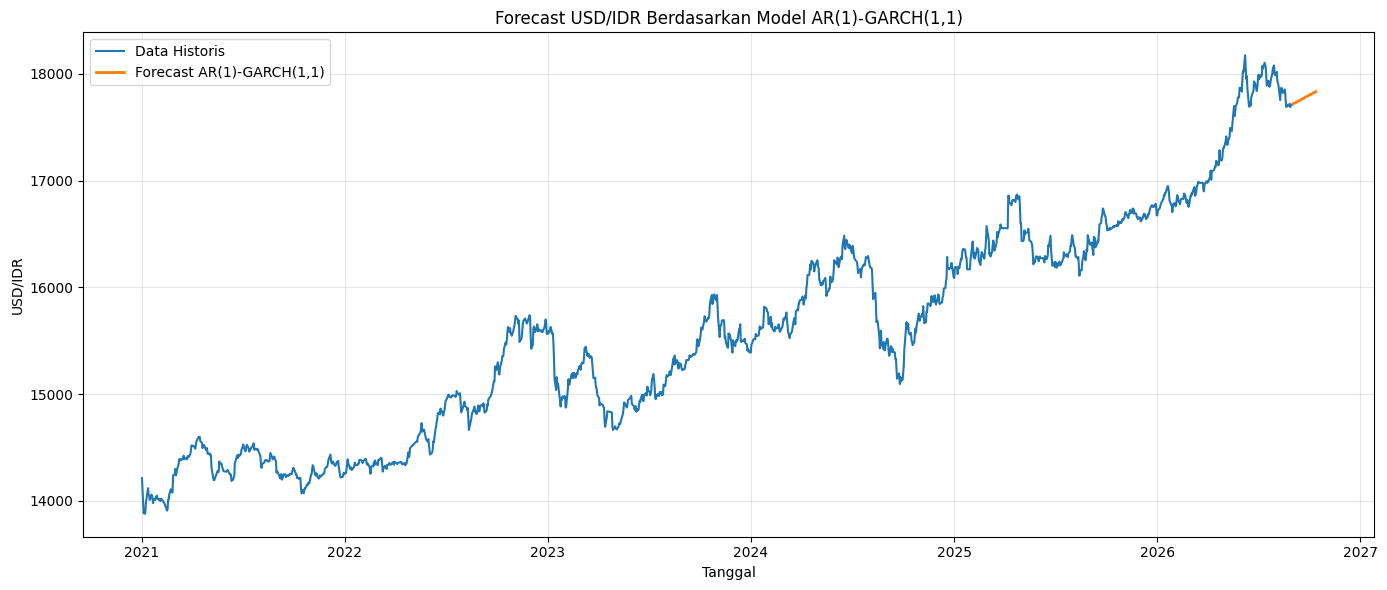

In [151]:
# ======================================
# PLOT HISTORIS + FORECAST
# ======================================

plt.figure(figsize=(14, 6))

plt.plot(
    y_historis.index,
    y_historis,
    label="Data Historis",
    linewidth=1.5
)

plt.plot(
    tanggal_forecast,
    forecast_level_historis,
    label="Forecast AR(1)-GARCH(1,1)",
    linewidth=2
)

plt.title(
    "Forecast USD/IDR Berdasarkan Model AR(1)-GARCH(1,1)"
)

plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [152]:
# ======================================
# ROLLING ONE-STEP-AHEAD FORECAST
# DATA HISTORIS
# ======================================

forecast_diff_historis = []
forecast_level_historis = []

# Data historis
y_historis = data["Terakhir"].copy()

# ======================================
# DIFFERENCING
# ======================================

y_historis_diff = y_historis.diff().dropna()

# ======================================
# SHIFT UNTUK BOX-COX
# ======================================

y_historis_shift = y_historis_diff + shift

# ======================================
# TRANSFORMASI BOX-COX
# ======================================

y_historis_boxcox = boxcox(
    y_historis_shift,
    lmbda=lambda_fit
)

y_historis_boxcox = pd.Series(
    y_historis_boxcox,
    index=y_historis_diff.index
)

# ======================================
# ROLLING FORECAST
# ======================================

# Mulai dari jumlah data training
# supaya konsisten dengan evaluasi testing
start = len(y_train_boxcox)

for i in range(len(y_historis_boxcox) - start):

    # ==================================
    # DATA YANG TERSEDIA
    # ==================================

    end_idx = start + i

    data_roll = y_historis_boxcox.iloc[:end_idx]

    # ==================================
    # MODEL AR(1)-GARCH(1,1)
    # ==================================

    model_roll = arch_model(
        data_roll,
        mean='ARX',
        lags=1,
        vol='GARCH',
        p=1,
        q=1,
        dist='normal'
    )

    hasil_roll = model_roll.fit(disp='off')

    # ==================================
    # FORECAST 1 LANGKAH
    # ==================================

    forecast_roll = hasil_roll.forecast(
        horizon=1,
        reindex=False
    )

    forecast_boxcox = forecast_roll.mean.iloc[-1, 0]

    # ==================================
    # INVERSE BOX-COX
    # ==================================

    if lambda_fit != 0:

        forecast_shift = (
            lambda_fit * forecast_boxcox + 1
        ) ** (1 / lambda_fit)

    else:

        forecast_shift = np.exp(
            forecast_boxcox
        )

    # ==================================
    # KEMBALIKAN SHIFT
    # ==================================

    forecast_d = forecast_shift - shift

    forecast_diff_historis.append(
        forecast_d
    )

    # ==================================
    # INVERSE DIFFERENCING
    # GUNAKAN AKTUAL SEBELUMNYA
    # ==================================

    current_idx = start + i

    if current_idx == 0:

        previous_actual = y_historis.iloc[
            current_idx
        ]

    else:

        previous_actual = y_historis.iloc[
            current_idx
        ]

    forecast_y = previous_actual + forecast_d

    forecast_level_historis.append(
        forecast_y
    )

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.082e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.081e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base

In [153]:
# ======================================
# ROLLING ONE-STEP-AHEAD FORECAST
# SELURUH PERIODE HISTORIS SETELAH TRAIN
# ======================================

forecast_level_historis = []

start = len(y_train)

for i in range(start, len(y_historis)):

    # ----------------------------------
    # DATA YANG TERSEDIA SEBELUM
    # OBSERVASI KE-i
    # ----------------------------------

    data_roll = y_historis_boxcox.iloc[:i-1]

    # ----------------------------------
    # FIT AR(1)-GARCH(1,1)
    # ----------------------------------

    model_roll = arch_model(
        data_roll,
        mean='ARX',
        lags=1,
        vol='GARCH',
        p=1,
        q=1,
        dist='normal'
    )

    hasil_roll = model_roll.fit(disp='off')

    # ----------------------------------
    # FORECAST 1 LANGKAH
    # ----------------------------------

    forecast_roll = hasil_roll.forecast(
        horizon=1,
        reindex=False
    )

    forecast_boxcox = forecast_roll.mean.iloc[-1, 0]

    # ----------------------------------
    # INVERSE BOX-COX
    # ----------------------------------

    if lambda_fit != 0:

        forecast_shift = (
            lambda_fit * forecast_boxcox + 1
        ) ** (1 / lambda_fit)

    else:

        forecast_shift = np.exp(
            forecast_boxcox
        )

    # ----------------------------------
    # HILANGKAN SHIFT
    # ----------------------------------

    forecast_d = forecast_shift - shift

    # ----------------------------------
    # INVERSE DIFFERENCING
    # ----------------------------------

    previous_actual = y_historis.iloc[i-1]

    forecast_y = previous_actual + forecast_d

    forecast_level_historis.append(
        forecast_y
    )

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.082e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.081e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base

In [154]:
forecast_level_historis = pd.Series(
    forecast_level_historis,
    index=y_historis.index[start:]
)

In [155]:
# ======================================
# TABEL FORECAST DATA HISTORIS
# ======================================

tabel_forecast_historis = pd.DataFrame({
    "Tanggal": y_historis.index[start:],
    "Aktual": y_historis.iloc[start:].values,
    "Forecast": forecast_level_historis.values
})

# Error
tabel_forecast_historis["Error"] = (
    tabel_forecast_historis["Aktual"]
    - tabel_forecast_historis["Forecast"]
)

# Absolute Error
tabel_forecast_historis["Absolute Error"] = (
    tabel_forecast_historis["Error"].abs()
)

# APE
tabel_forecast_historis["APE (%)"] = (
    np.abs(
        tabel_forecast_historis["Error"]
        / tabel_forecast_historis["Aktual"]
    ) * 100
)

display(tabel_forecast_historis.head(20))

,Tanggal,Aktual,Forecast,Error,Absolute Error,APE (%)
0,2026-07-06,17990.0,17951.572231,38.427769,38.427769,0.213606
1,2026-07-07,17975.0,17996.015926,-21.015926,21.015926,0.116918
2,2026-07-08,17994.0,17978.115743,15.884257,15.884257,0.088275
3,2026-07-09,18075.0,17998.841439,76.158561,76.158561,0.421347
4,2026-07-10,18050.0,18083.672982,-33.672982,33.672982,0.186554
5,2026-07-13,18105.0,18052.620981,52.379019,52.379019,0.289307
6,2026-07-14,18085.0,18112.087989,-27.087989,27.087989,0.149782
7,2026-07-15,18065.0,18087.921328,-22.921328,22.921328,0.126883
8,2026-07-16,17985.0,18067.910993,-82.910993,82.910993,0.461001
9,2026-07-17,17890.0,17984.792953,-94.792953,94.792953,0.529866


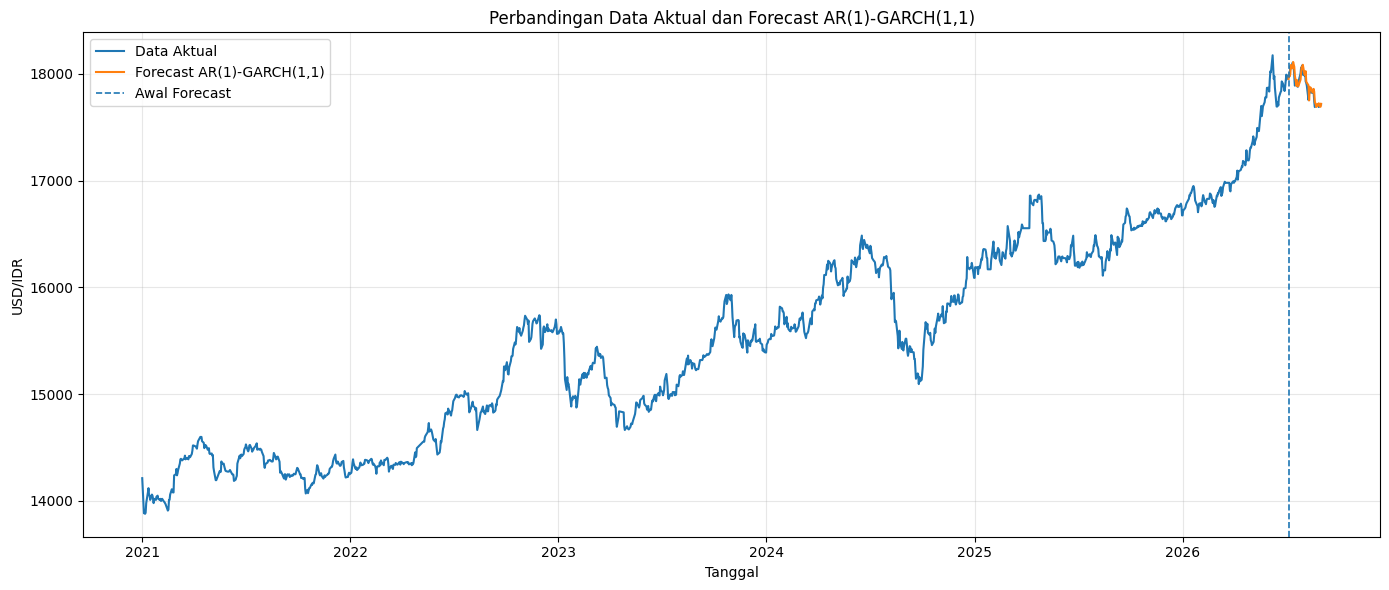

In [156]:
# ======================================
# PLOT AKTUAL VS FORECAST
# ======================================

plt.figure(figsize=(14, 6))

plt.plot(
    y_historis.index,
    y_historis,
    label="Data Aktual",
    linewidth=1.5
)

plt.plot(
    tabel_forecast_historis["Tanggal"],
    tabel_forecast_historis["Forecast"],
    label="Forecast AR(1)-GARCH(1,1)",
    linewidth=1.5
)

# Garis pemisah awal forecast
plt.axvline(
    y_historis.index[start],
    linestyle="--",
    linewidth=1.2,
    label="Awal Forecast"
)

plt.title(
    "Perbandingan Data Aktual dan Forecast "
    "AR(1)-GARCH(1,1)"
)

plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# **LSTM**

Rancangan LSTM

Data training : 1.400 observasi
Untuk melatih model LSTM.

Data testing : 42 observasi
Untuk evaluasi.

Model LSTM
Menggunakan 20 observasi sebelumnya untuk memprediksi satu observasi berikutnya.

## Menyiapkan Data

In [157]:
# ======================================
# PERSIAPAN DATA LSTM
# ======================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Data harga training dan testing
train_values = np.asarray(y_train, dtype=float).reshape(-1, 1)
test_values = np.asarray(y_test, dtype=float).reshape(-1, 1)

# Normalisasi: scaler hanya dilatih pada training
scaler_lstm = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler_lstm.fit_transform(train_values)
test_scaled = scaler_lstm.transform(test_values)

# Panjang urutan input
look_back = 20

print("Jumlah training :", len(train_values))
print("Jumlah testing  :", len(test_values))
print("Look-back       :", look_back)

Jumlah training : 1400
Jumlah testing  : 42
Look-back       : 20


## Membentuk Urutan Input

In [158]:
# ======================================
# MEMBENTUK SEQUENCE TRAINING
# ======================================

X_train_lstm = []
y_train_lstm = []

for i in range(look_back, len(train_scaled)):
    X_train_lstm.append(
        train_scaled[i - look_back:i, 0]
    )
    y_train_lstm.append(
        train_scaled[i, 0]
    )

X_train_lstm = np.array(X_train_lstm).reshape(
    -1, look_back, 1
)

y_train_lstm = np.array(y_train_lstm)

# ======================================
# MEMBENTUK SEQUENCE TESTING
# ======================================

# Gabungkan nilai terskala untuk membentuk
# urutan historis sebelum setiap target testing.
all_scaled = np.vstack([
    train_scaled,
    test_scaled
])

X_test_lstm = []

for i in range(len(test_scaled)):
    end_idx = len(train_scaled) + i

    X_test_lstm.append(
        all_scaled[end_idx - look_back:end_idx, 0]
    )

X_test_lstm = np.array(X_test_lstm).reshape(
    -1, look_back, 1
)

print("Bentuk X_train :", X_train_lstm.shape)
print("Bentuk y_train :", y_train_lstm.shape)
print("Bentuk X_test  :", X_test_lstm.shape)

Bentuk X_train : (1380, 20, 1)
Bentuk y_train : (1380,)
Bentuk X_test  : (42, 20, 1)


## Membangun dan Melatih Model LSTM

In [159]:
# ======================================
# PEMODELAN LSTM
# ======================================

model_lstm = Sequential([
    LSTM(
        units=50,
        input_shape=(look_back, 1)
    ),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

model_lstm.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - loss: 0.0033 - val_loss: 0.0049
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0033 - val_loss: 7.2737e-04
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0012 - val_loss: 4.9745e-04
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 7.4733e-04 - val_loss: 5.3020e-04
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 7.4563e-04 - val_loss: 5.6507e-04
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 7.5369e-04 - val_loss: 5.9536e-04
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.5140e-04 - val_loss: 6.1879e-04
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.3717e-04 - val_loss: 6.3280e-04
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 7.0977e-04 - val_loss: 6.4265e-04
Epoch 10/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.7349e-04 - val_loss: 6.5234e-04
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.3322e-04 - v

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

In [160]:
import pandas as pd

parameter_lstm = pd.DataFrame({
    "Parameter": [
        "units = 50",
        "look_back = 20",
        "epochs = 100",
        "batch_size = 32",
        "patience = 10"
    ],
    "Makna": [
        "Jumlah unit pada lapisan LSTM",
        "Panjang urutan input, yaitu 20 observasi sebelumnya",
        "Batas maksimum jumlah epoch pelatihan",
        "Jumlah sampel yang diproses dalam satu batch",
        "Menghentikan pelatihan jika val_loss tidak membaik selama 10 epoch"
    ]
})

display(parameter_lstm)

,Parameter,Makna
0,units = 50,Jumlah unit pada lapisan LSTM
1,look_back = 20,"Panjang urutan input, yaitu 20 observasi sebel..."
2,epochs = 100,Batas maksimum jumlah epoch pelatihan
3,batch_size = 32,Jumlah sampel yang diproses dalam satu batch
4,patience = 10,Menghentikan pelatihan jika val_loss tidak mem...


## Melakukan Peramalan Data Testing

In [161]:
# ======================================
# FORECASTING LSTM
# ======================================

# Prediksi dalam skala normalisasi
pred_scaled_lstm = model_lstm.predict(
    X_test_lstm,
    verbose=0
)

# Mengembalikan ke skala USD/IDR
forecast_lstm = scaler_lstm.inverse_transform(
    pred_scaled_lstm
).ravel()

aktual_test = test_values.ravel()

# Menentukan tanggal testing
if "Tanggal" in test.columns:
    tanggal_test = pd.to_datetime(
        test["Tanggal"]
    ).reset_index(drop=True)
else:
    tanggal_test = pd.to_datetime(test.index)

# Tabel hasil forecast
tabel_forecast_lstm = pd.DataFrame({
    "Tanggal": tanggal_test,
    "Aktual": aktual_test,
    "Forecast LSTM": forecast_lstm
})

display(tabel_forecast_lstm)

,Tanggal,Aktual,Forecast LSTM
0,2026-07-06,17990.0,17938.125000
1,2026-07-07,17975.0,17950.367188
2,2026-07-08,17994.0,17962.732422
3,2026-07-09,18075.0,17974.828125
4,2026-07-10,18050.0,17990.251953
5,2026-07-13,18105.0,18006.716797
6,2026-07-14,18085.0,18024.626953
7,2026-07-15,18065.0,18042.064453
8,2026-07-16,17985.0,18056.367188
9,2026-07-17,17890.0,18064.031250


## Evaluasi Akurasi LSTM

In [162]:
# ======================================
# EVALUASI LSTM
# ======================================

mse_lstm = mean_squared_error(
    aktual_test, forecast_lstm
)

rmse_lstm = np.sqrt(mse_lstm)

mae_lstm = mean_absolute_error(
    aktual_test, forecast_lstm
)

mape_lstm = np.mean(
    np.abs(
        (aktual_test - forecast_lstm)
        / aktual_test
    )
) * 100

print("======================================")
print("EVALUASI FORECAST LSTM")
print("======================================")
print(f"MSE  : {mse_lstm:.4f}")
print(f"RMSE : {rmse_lstm:.4f}")
print(f"MAE  : {mae_lstm:.4f}")
print(f"MAPE : {mape_lstm:.4f}%")

EVALUASI FORECAST LSTM
MSE  : 15239.0663
RMSE : 123.4466
MAE  : 108.1916
MAPE : 0.6062%


## Perbandingan dengan GARCH

In [163]:
# ======================================
# PERBANDINGAN GARCH DAN LSTM
# ======================================

perbandingan_model = pd.DataFrame({
    "Model": [
        "AR(1)-GARCH(1,1)",
        "LSTM"
    ],
    "RMSE": [
        rmse,
        rmse_lstm
    ],
    "MAE": [
        mae,
        mae_lstm
    ],
    "MAPE (%)": [
        mape,
        mape_lstm
    ]
})

display(perbandingan_model)

,Model,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",50.228859,39.624466,0.221312
1,LSTM,123.446613,108.191639,0.606217


## Visualisasi hasil LSTM

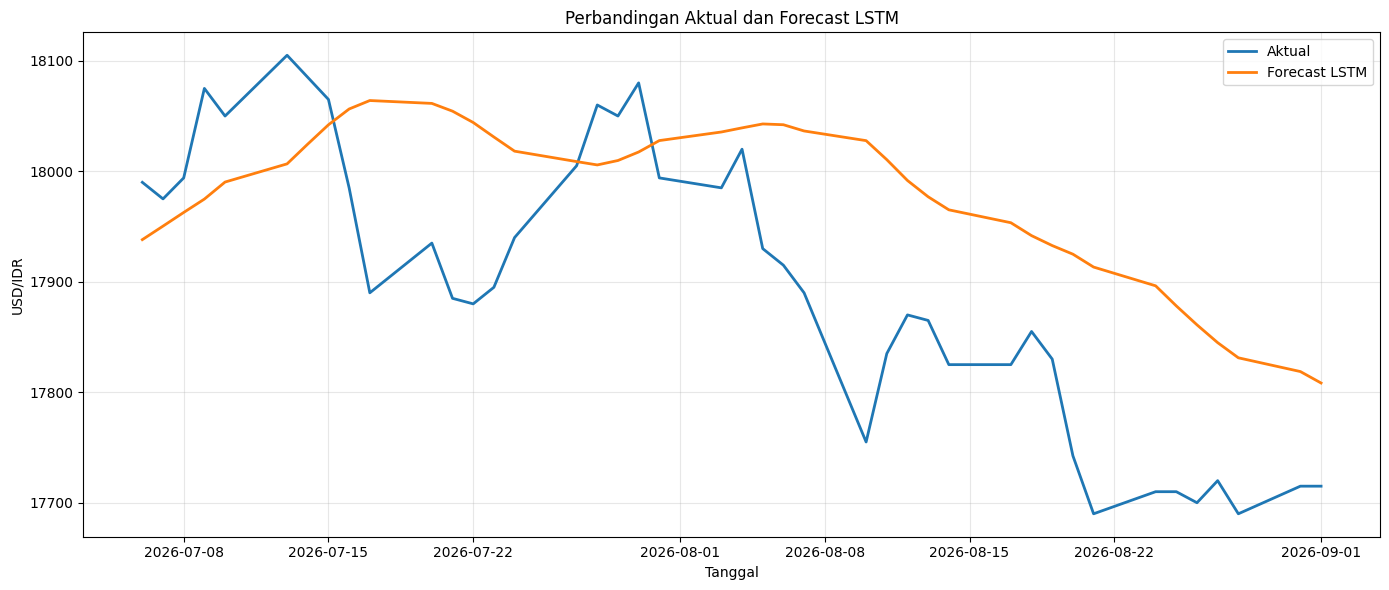

In [164]:
# ======================================
# PLOT AKTUAL VS FORECAST LSTM
# ======================================

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test,
    aktual_test,
    label="Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test,
    forecast_lstm,
    label="Forecast LSTM",
    linewidth=2
)

plt.title("Perbandingan Aktual dan Forecast LSTM")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Eksperimen Kedua dengan LSTM

## Persiapan Data

In [165]:
# ======================================
# LSTM ALTERNATIF: BERBASIS LOG RETURN
# 1. PERSIAPAN DATA
# ======================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Mengambil data training dan testing
price_train_return = y_train.copy().astype(float)
price_test_return = y_test.copy().astype(float)

# Menggabungkan data berdasarkan urutan tanggal
price_all_return = pd.concat([
    price_train_return,
    price_test_return
]).sort_index()

print("Jumlah training :", len(price_train_return))
print("Jumlah testing  :", len(price_test_return))
print("Periode training:", price_train_return.index.min(),
      "sampai", price_train_return.index.max())
print("Periode testing :", price_test_return.index.min(),
      "sampai", price_test_return.index.max())

Jumlah training : 1400
Jumlah testing  : 42
Periode training: 0 sampai 1399
Periode testing : 1400 sampai 1441


## Menghitung log return

In [166]:
# ======================================
# 2. TRANSFORMASI LOG RETURN
# ======================================

return_all_lstm = 100 * np.log(
    price_all_return / price_all_return.shift(1)
)

# Return untuk training
return_train_lstm = return_all_lstm.loc[
    price_train_return.index
].dropna()

# Return untuk testing
return_test_lstm = return_all_lstm.loc[
    price_test_return.index
].dropna()

print("Jumlah return training :", len(return_train_lstm))
print("Jumlah return testing  :", len(return_test_lstm))

display(return_train_lstm.head())

Jumlah return training : 1399
Jumlah return testing  : 42


,Terakhir
1,-2.339717
2,0.107972
3,-0.143989
4,0.072020
5,0.645858


## Normalisasi data

In [167]:
# ======================================
# 3. NORMALISASI LOG RETURN
# ======================================

scaler_return_lstm = MinMaxScaler(
    feature_range=(0, 1)
)

# Scaler hanya dilatih pada data training
train_scaled_return = scaler_return_lstm.fit_transform(
    return_train_lstm.to_numpy().reshape(-1, 1)
)

# Transformasi semua return dengan scaler training
return_clean_lstm = return_all_lstm.dropna()

all_scaled_return = scaler_return_lstm.transform(
    return_clean_lstm.to_numpy().reshape(-1, 1)
).ravel()

print("Normalisasi data selesai.")

Normalisasi data selesai.


## Membentuk sequence input LSTM

In [168]:
# ======================================
# 4. PEMBENTUKAN SEQUENCE
# ======================================

look_back_return = 20

X_train_return = []
y_train_return = []

# Sequence training
for i in range(
    look_back_return,
    len(train_scaled_return)
):
    X_train_return.append(
        train_scaled_return[
            i - look_back_return:i, 0
        ]
    )

    y_train_return.append(
        train_scaled_return[i, 0]
    )

X_train_return = np.array(
    X_train_return
).reshape(-1, look_back_return, 1)

y_train_return = np.array(y_train_return)

# Sequence testing
X_test_return = []

for tanggal in return_test_lstm.index:

    posisi = return_clean_lstm.index.get_loc(tanggal)

    X_test_return.append(
        all_scaled_return[
            posisi - look_back_return:posisi
        ]
    )

X_test_return = np.array(
    X_test_return
).reshape(-1, look_back_return, 1)

print("Shape X_train:", X_train_return.shape)
print("Shape y_train:", y_train_return.shape)
print("Shape X_test :", X_test_return.shape)

Shape X_train: (1379, 20, 1)
Shape y_train: (1379,)
Shape X_test : (42, 20, 1)


## Membangun dan melatih model LSTM

In [169]:
# ======================================
# 5. PEMODELAN LSTM
# ======================================

model_lstm_return = Sequential([
    Input(shape=(look_back_return, 1)),
    LSTM(
        units=32,
        dropout=0.1
    ),
    Dense(1)
])

model_lstm_return.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

early_stop_return = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm_return = model_lstm_return.fit(
    X_train_return,
    y_train_return,
    epochs=150,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_return],
    verbose=1
)

model_lstm_return.summary()

Epoch 1/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - loss: 0.0756 - val_loss: 0.0095
Epoch 2/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0174 - val_loss: 0.0060
Epoch 3/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0132 - val_loss: 0.0050
Epoch 4/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0070 - val_loss: 0.0050
Epoch 5/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 6/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 7/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 8/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 9/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 10/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 11/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0058 - val_loss: 0.0051
Epoch 12/150
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - los

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,157 (51.40 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,772 (34.27 KB)

## Forecasting log return dan konversi ke harga

In [170]:
# ======================================
# 6. FORECASTING LOG RETURN
# ======================================

pred_scaled_return = model_lstm_return.predict(
    X_test_return,
    verbose=0
)

# Mengembalikan prediksi ke skala log return
forecast_return = scaler_return_lstm.inverse_transform(
    pred_scaled_return
).ravel()

# Tanggal testing yang memiliki target return
tanggal_test_return = return_test_lstm.index

# Harga aktual pada periode testing
aktual_test_return = price_test_return.reindex(
    tanggal_test_return
).to_numpy()

# Harga aktual satu observasi sebelumnya
harga_sebelumnya_return = price_all_return.shift(1).reindex(
    tanggal_test_return
).to_numpy()

# Mengonversi prediksi return menjadi harga
forecast_lstm_return = (
    harga_sebelumnya_return
    * np.exp(forecast_return / 100)
)

print("Forecast log return selesai.")
print("Jumlah prediksi:", len(forecast_lstm_return))

Forecast log return selesai.
Jumlah prediksi: 42


## Evaluasi hasil LSTM

In [171]:
# ======================================
# 7. EVALUASI FORECAST LSTM
# ======================================

mse_lstm_return = mean_squared_error(
    aktual_test_return,
    forecast_lstm_return
)

rmse_lstm_return = np.sqrt(
    mse_lstm_return
)

mae_lstm_return = mean_absolute_error(
    aktual_test_return,
    forecast_lstm_return
)

mape_lstm_return = np.mean(
    np.abs(
        (aktual_test_return - forecast_lstm_return)
        / aktual_test_return
    )
) * 100

hasil_evaluasi_lstm_return = pd.DataFrame({
    "Metrik": ["MSE", "RMSE", "MAE", "MAPE (%)"],
    "Nilai": [
        mse_lstm_return,
        rmse_lstm_return,
        mae_lstm_return,
        mape_lstm_return
    ]
})

display(hasil_evaluasi_lstm_return)

,Metrik,Nilai
0,MSE,2542.332438
1,RMSE,50.421547
2,MAE,39.807832
3,MAPE (%),0.222348


## Membuat tabel hasil forecasting

In [172]:
# ======================================
# 8. TABEL HASIL FORECAST
# ======================================

tabel_forecast_lstm_return = pd.DataFrame({
    "Tanggal": tanggal_test_return,
    "Aktual": aktual_test_return,
    "Forecast LSTM Log Return": forecast_lstm_return
})

display(tabel_forecast_lstm_return)

,Tanggal,Aktual,Forecast LSTM Log Return
0,1400,17990.0,17956.186181
1,1401,17975.0,17996.802592
2,1402,17994.0,17980.611959
3,1403,18075.0,17999.669372
4,1404,18050.0,18082.448825
5,1405,18105.0,18055.852699
6,1406,18085.0,18111.841761
7,1407,18065.0,18090.590249
8,1408,17985.0,18069.658055
9,1409,17890.0,17987.240458


## Visualisasi aktual dan forecast

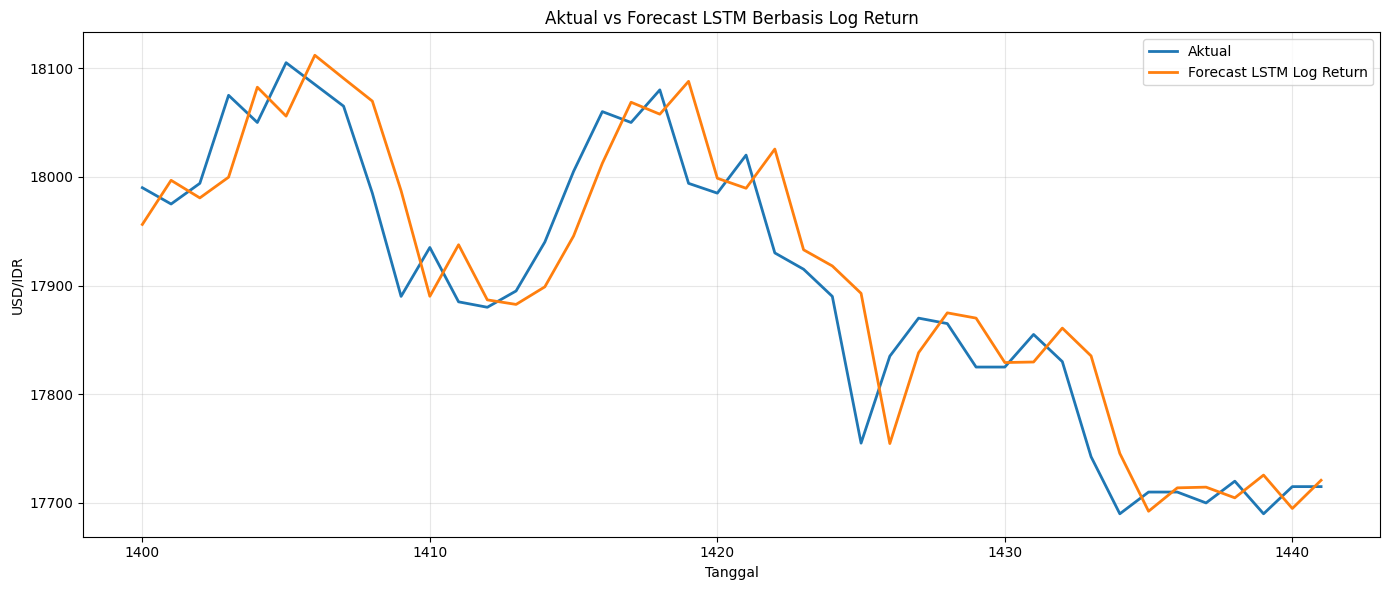

In [173]:
# ======================================
# 9. VISUALISASI FORECAST
# ======================================

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test_return,
    aktual_test_return,
    label="Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test_return,
    forecast_lstm_return,
    label="Forecast LSTM Log Return",
    linewidth=2
)

plt.title("Aktual vs Forecast LSTM Berbasis Log Return")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Membandingkan dua eksperimen LSTM

In [174]:
# ======================================
# 10. PERBANDINGAN DUA MODEL LSTM
# ======================================

perbandingan_lstm = pd.DataFrame({
    "Model": [
        "LSTM Harga Langsung",
        "LSTM Berbasis Log Return"
    ],
    "RMSE": [
        rmse_lstm,
        rmse_lstm_return
    ],
    "MAE": [
        mae_lstm,
        mae_lstm_return
    ],
    "MAPE (%)": [
        mape_lstm,
        mape_lstm_return
    ]
})

display(perbandingan_lstm)

,Model,RMSE,MAE,MAPE (%)
0,LSTM Harga Langsung,123.446613,108.191639,0.606217
1,LSTM Berbasis Log Return,50.421547,39.807832,0.222348


In [175]:
# ======================================
# VALIDASI LSTM LOG RETURN
# 1. CEK DATA, INDEKS, DAN TANGGAL
# ======================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

# Posisi observasi training dan testing
idx_train = y_train.index.to_numpy(dtype=int)
idx_test = y_test.index.to_numpy(dtype=int)

# Memastikan indeks data sudah berupa tanggal
assert isinstance(data.index, pd.DatetimeIndex), (
    "Indeks data belum berupa DatetimeIndex."
)

# Mengambil tanggal sesuai posisi observasi asli
tanggal_train_validasi = data.index.take(idx_train)
tanggal_test_validasi = data.index.take(idx_test)

# Mengambil nilai aktual langsung dari data
aktual_dari_data = data["Terakhir"].iloc[
    idx_test
].to_numpy(dtype=float)

# Mengambil hasil aktual dan prediksi LSTM
aktual_dari_lstm = np.asarray(
    aktual_test_return, dtype=float
).ravel()

forecast_dari_lstm = np.asarray(
    forecast_lstm_return, dtype=float
).ravel()

return_prediksi = np.asarray(
    forecast_return, dtype=float
).ravel()

# ======================================
# PEMERIKSAAN JUMLAH OBSERVASI
# ======================================

print("======================================")
print("PEMERIKSAAN JUMLAH OBSERVASI")
print("======================================")

print("Jumlah training          :", len(y_train))
print("Jumlah testing           :", len(y_test))
print("Jumlah aktual dari data  :", len(aktual_dari_data))
print("Jumlah aktual LSTM       :", len(aktual_dari_lstm))
print("Jumlah forecast LSTM     :", len(forecast_dari_lstm))

assert len(y_train) == 1400, "Jumlah training tidak sesuai."
assert len(y_test) == 42, "Jumlah testing tidak sesuai."

assert len(aktual_dari_data) == 42
assert len(aktual_dari_lstm) == 42
assert len(forecast_dari_lstm) == 42
assert len(return_prediksi) == 42

# ======================================
# PEMERIKSAAN PERIODE TANGGAL
# ======================================

print("\n======================================")
print("PEMERIKSAAN PERIODE")
print("======================================")

print(
    "Periode training:",
    tanggal_train_validasi.min(),
    "sampai",
    tanggal_train_validasi.max()
)

print(
    "Periode testing :",
    tanggal_test_validasi.min(),
    "sampai",
    tanggal_test_validasi.max()
)

assert tanggal_test_validasi.min() == pd.Timestamp("2026-07-06")
assert tanggal_test_validasi.max() == pd.Timestamp("2026-09-01")

# ======================================
# PEMERIKSAAN KESESUAIAN NILAI AKTUAL
# ======================================

print("\n======================================")
print("PEMERIKSAAN NILAI AKTUAL")
print("======================================")

# Nilai aktual dari data harus sama dengan y_test
assert np.allclose(
    aktual_dari_data,
    y_test.to_numpy(dtype=float)
), "Nilai aktual dari data tidak cocok dengan y_test."

# Nilai aktual yang digunakan dalam evaluasi LSTM
# harus sama dengan nilai aktual dari data
assert np.allclose(
    aktual_dari_data,
    aktual_dari_lstm
), "Nilai aktual LSTM tidak sejajar dengan data testing."

print("Nilai aktual sesuai dengan data testing.")

# ======================================
# PEMERIKSAAN PERHITUNGAN FORECAST
# ======================================

# Harga aktual satu observasi sebelum setiap tanggal testing
harga_sebelumnya_validasi = price_all_return.shift(1).reindex(
    y_test.index
).to_numpy(dtype=float)

# Menghitung ulang forecast dari prediksi log return
forecast_hitung_ulang = (
    harga_sebelumnya_validasi
    * np.exp(return_prediksi / 100)
)

assert np.allclose(
    forecast_dari_lstm,
    forecast_hitung_ulang
), "Perhitungan forecast tidak konsisten."

assert np.isfinite(forecast_dari_lstm).all()
assert np.isfinite(aktual_dari_data).all()

print("Perhitungan forecast konsisten.")
print("\nSemua pemeriksaan utama berhasil.")

PEMERIKSAAN JUMLAH OBSERVASI
Jumlah training          : 1400
Jumlah testing           : 42
Jumlah aktual dari data  : 42
Jumlah aktual LSTM       : 42
Jumlah forecast LSTM     : 42

PEMERIKSAAN PERIODE
Periode training: 2021-01-01 00:00:00 sampai 2026-07-03 00:00:00
Periode testing : 2026-07-06 00:00:00 sampai 2026-09-01 00:00:00

PEMERIKSAAN NILAI AKTUAL
Nilai aktual sesuai dengan data testing.
Perhitungan forecast konsisten.

Semua pemeriksaan utama berhasil.


In [176]:
# ======================================
# TABEL VALIDASI FORECAST LSTM
# ======================================

tabel_validasi_lstm = pd.DataFrame({
    "Tanggal": tanggal_test_validasi,
    "Aktual": aktual_dari_data,
    "Aktual yang Dievaluasi": aktual_dari_lstm,
    "Forecast LSTM Log Return": forecast_dari_lstm
})

tabel_validasi_lstm["Selisih Aktual"] = (
    tabel_validasi_lstm["Aktual"]
    - tabel_validasi_lstm["Aktual yang Dievaluasi"]
)

tabel_validasi_lstm["Error Forecast"] = (
    tabel_validasi_lstm["Aktual"]
    - tabel_validasi_lstm["Forecast LSTM Log Return"]
)

display(tabel_validasi_lstm)

,Tanggal,Aktual,Aktual yang Dievaluasi,Forecast LSTM Log Return,Selisih Aktual,Error Forecast
0,2026-07-06,17990.0,17990.0,17956.186181,0.0,33.813819
1,2026-07-07,17975.0,17975.0,17996.802592,0.0,-21.802592
2,2026-07-08,17994.0,17994.0,17980.611959,0.0,13.388041
3,2026-07-09,18075.0,18075.0,17999.669372,0.0,75.330628
4,2026-07-10,18050.0,18050.0,18082.448825,0.0,-32.448825
5,2026-07-13,18105.0,18105.0,18055.852699,0.0,49.147301
6,2026-07-14,18085.0,18085.0,18111.841761,0.0,-26.841761
7,2026-07-15,18065.0,18065.0,18090.590249,0.0,-25.590249
8,2026-07-16,17985.0,17985.0,18069.658055,0.0,-84.658055
9,2026-07-17,17890.0,17890.0,17987.240458,0.0,-97.240458


In [177]:
# ======================================
# VALIDASI METRIK EVALUASI
# ======================================

rmse_validasi = np.sqrt(
    mean_squared_error(
        aktual_dari_data,
        forecast_dari_lstm
    )
)

mae_validasi = mean_absolute_error(
    aktual_dari_data,
    forecast_dari_lstm
)

mape_validasi = np.mean(
    np.abs(
        (aktual_dari_data - forecast_dari_lstm)
        / aktual_dari_data
    )
) * 100

hasil_validasi_metrik = pd.DataFrame({
    "Metrik": ["RMSE", "MAE", "MAPE (%)"],
    "Hasil Validasi": [
        rmse_validasi,
        mae_validasi,
        mape_validasi
    ],
    "Hasil Sebelumnya": [
        rmse_lstm_return,
        mae_lstm_return,
        mape_lstm_return
    ]
})

display(hasil_validasi_metrik)

,Metrik,Hasil Validasi,Hasil Sebelumnya
0,RMSE,50.421547,50.421547
1,MAE,39.807832,39.807832
2,MAPE (%),0.222348,0.222348


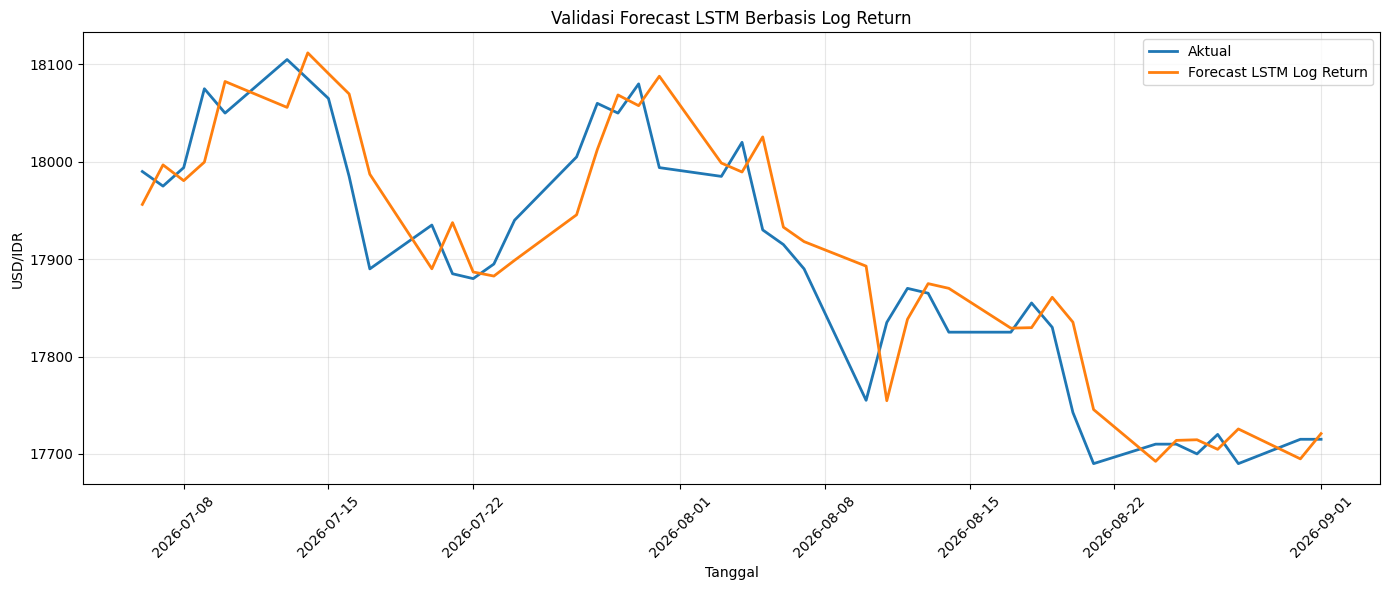

In [178]:
# ======================================
# AKTUAL VS FORECAST DENGAN TANGGAL ASLI
# ======================================

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test_validasi,
    aktual_dari_data,
    label="Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test_validasi,
    forecast_dari_lstm,
    label="Forecast LSTM Log Return",
    linewidth=2
)

plt.title("Validasi Forecast LSTM Berbasis Log Return")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Menghitung dan membandingkan metrik evaluasi

In [179]:
# ======================================
# PERBANDINGAN AR(1)-GARCH(1,1) VS LSTM
# ======================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ======================================
# 1. MENYIAPKAN DATA AKTUAL DAN FORECAST
# ======================================

aktual_compare = y_test.astype(float).copy()

# Forecast GARCH yang sudah dihitung sebelumnya
forecast_garch_compare = pd.Series(
    forecast_level,
    index=forecast_level.index
).reindex(aktual_compare.index)

# Forecast LSTM berbasis log return
forecast_lstm_compare = pd.Series(
    forecast_lstm_return,
    index=return_test_lstm.index
).reindex(aktual_compare.index)

# Memastikan tidak ada nilai yang hilang
assert len(aktual_compare) == 42
assert forecast_garch_compare.notna().all()
assert forecast_lstm_compare.notna().all()

# ======================================
# 2. FUNGSI EVALUASI
# ======================================

def evaluasi_forecast(aktual, prediksi):

    mse = mean_squared_error(aktual, prediksi)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(aktual, prediksi)

    mape = np.mean(
        np.abs((aktual - prediksi) / aktual)
    ) * 100

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    }

# ======================================
# 3. EVALUASI KEDUA MODEL
# ======================================

hasil_garch_compare = evaluasi_forecast(
    aktual_compare.to_numpy(),
    forecast_garch_compare.to_numpy()
)

hasil_lstm_compare = evaluasi_forecast(
    aktual_compare.to_numpy(),
    forecast_lstm_compare.to_numpy()
)

# ======================================
# 4. TABEL PERBANDINGAN
# ======================================

tabel_perbandingan = pd.DataFrame([
    {
        "Model": "AR(1)-GARCH(1,1)",
        **hasil_garch_compare
    },
    {
        "Model": "LSTM Log Return",
        **hasil_lstm_compare
    }
])

print("======================================")
print("PERBANDINGAN AKURASI MODEL")
print("======================================")

display(
    tabel_perbandingan.round(4)
)

PERBANDINGAN AKURASI MODEL


,Model,MSE,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",2522.9383,50.2289,39.6245,0.2213
1,LSTM Log Return,2542.3324,50.4215,39.8078,0.2223


## Membuat tabel prediksi kedua model

In [180]:
# ======================================
# TABEL AKTUAL DAN FORECAST KEDUA MODEL
# ======================================

tabel_forecast_compare = pd.DataFrame({
    "Tanggal": tanggal_test_validasi,
    "Aktual": aktual_compare.to_numpy(),
    "Forecast GARCH": forecast_garch_compare.to_numpy(),
    "Forecast LSTM": forecast_lstm_compare.to_numpy()
})

tabel_forecast_compare["Error GARCH"] = (
    tabel_forecast_compare["Aktual"]
    - tabel_forecast_compare["Forecast GARCH"]
)

tabel_forecast_compare["Error LSTM"] = (
    tabel_forecast_compare["Aktual"]
    - tabel_forecast_compare["Forecast LSTM"]
)

display(tabel_forecast_compare.round(4))

,Tanggal,Aktual,Forecast GARCH,Forecast LSTM,Error GARCH,Error LSTM
0,2026-07-06,17990.0,17951.5722,17956.1862,38.4278,33.8138
1,2026-07-07,17975.0,17996.0159,17996.8026,-21.0159,-21.8026
2,2026-07-08,17994.0,17978.1157,17980.6120,15.8843,13.3880
3,2026-07-09,18075.0,17998.8414,17999.6694,76.1586,75.3306
4,2026-07-10,18050.0,18083.6730,18082.4488,-33.6730,-32.4488
5,2026-07-13,18105.0,18052.6210,18055.8527,52.3790,49.1473
6,2026-07-14,18085.0,18112.0880,18111.8418,-27.0880,-26.8418
7,2026-07-15,18065.0,18087.9213,18090.5902,-22.9213,-25.5902
8,2026-07-16,17985.0,18067.9110,18069.6581,-82.9110,-84.6581
9,2026-07-17,17890.0,17984.7930,17987.2405,-94.7930,-97.2405


## Visualisasi perbandingan

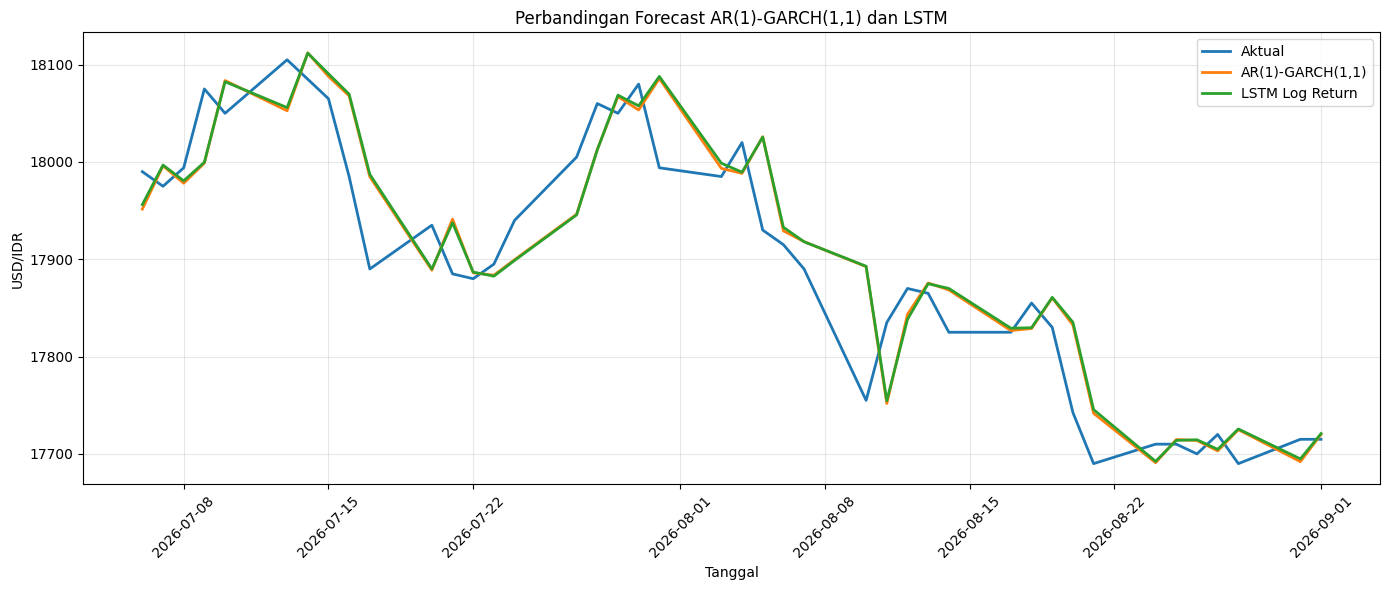

In [181]:
# ======================================
# PLOT PERBANDINGAN FORECAST
# ======================================

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_test_validasi,
    aktual_compare.to_numpy(),
    label="Aktual",
    linewidth=2
)

plt.plot(
    tanggal_test_validasi,
    forecast_garch_compare.to_numpy(),
    label="AR(1)-GARCH(1,1)",
    linewidth=2
)

plt.plot(
    tanggal_test_validasi,
    forecast_lstm_compare.to_numpy(),
    label="LSTM Log Return",
    linewidth=2
)

plt.title("Perbandingan Forecast AR(1)-GARCH(1,1) dan LSTM")
plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **HYBRID GARCH-LSTM**

## Melatih LSTM dari residual GARCH

In [182]:
# ======================================
# HYBRID GARCH-LSTM
# 1. PERSIAPAN RESIDUAL TRAINING
# ======================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

# Gunakan residual mentah dari model GARCH training
# Residual ini berada pada skala Box-Cox differencing
resid_train_hybrid = (
    hasil_garch.resid.dropna().astype(float)
)

print("Jumlah residual training:",
      len(resid_train_hybrid))

print("Rata-rata residual:",
      resid_train_hybrid.mean())

print("Standar deviasi residual:",
      resid_train_hybrid.std())

# ======================================
# 2. NORMALISASI RESIDUAL
# ======================================

scaler_resid_hybrid = StandardScaler()

resid_scaled_hybrid = scaler_resid_hybrid.fit_transform(
    resid_train_hybrid.to_numpy().reshape(-1, 1)
)

# ======================================
# 3. PEMBENTUKAN SEQUENCE
# ======================================

look_back_resid_hybrid = 20

X_train_resid_hybrid = []
y_train_resid_hybrid = []

for i in range(
    look_back_resid_hybrid,
    len(resid_scaled_hybrid)
):
    X_train_resid_hybrid.append(
        resid_scaled_hybrid[
            i - look_back_resid_hybrid:i, 0
        ]
    )

    y_train_resid_hybrid.append(
        resid_scaled_hybrid[i, 0]
    )

X_train_resid_hybrid = np.array(
    X_train_resid_hybrid
).reshape(-1, look_back_resid_hybrid, 1)

y_train_resid_hybrid = np.array(
    y_train_resid_hybrid
)

print("Shape X residual:",
      X_train_resid_hybrid.shape)

print("Shape y residual:",
      y_train_resid_hybrid.shape)

Jumlah residual training: 1398
Rata-rata residual: 1.528794035736706
Standar deviasi residual: 456.45805045067283
Shape X residual: (1378, 20, 1)
Shape y residual: (1378,)


## Membangun model LSTM residual

In [183]:
# ======================================
# 4. PEMODELAN LSTM RESIDUAL
# ======================================

model_lstm_resid = Sequential([
    Input(
        shape=(look_back_resid_hybrid, 1)
    ),
    LSTM(
        units=16,
        dropout=0.1
    ),
    Dense(1)
])

model_lstm_resid.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

early_stop_resid = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_lstm_resid = model_lstm_resid.fit(
    X_train_resid_hybrid,
    y_train_resid_hybrid,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_resid],
    verbose=1
)

model_lstm_resid.summary()

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.9946 - val_loss: 1.1140
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9929 - val_loss: 1.1084
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.9916 - val_loss: 1.1059
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9913 - val_loss: 1.1031
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.9909 - val_loss: 1.1018
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.9889 - val_loss: 1.1012
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.9878 - val_loss: 1.0991
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.9898 - val_loss: 1.0970
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.9876 - val_loss: 1.0952
Epoch 10/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9867 - val_loss: 1.0941
Epoch 11/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9866 - val_loss: 1.0930
Epoch 12/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - los

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,509 (13.71 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,340 (9.14 KB)

## Melakukan rolling forecast hybrid

In [184]:
# ======================================
# 5. PERSIAPAN DATA BOX-COX LENGKAP
# ======================================

from scipy.stats import boxcox
from arch import arch_model

# Gabungkan training dan testing
y_all_hybrid = pd.concat([
    y_train,
    y_test
]).sort_index()

# Differencing
y_all_diff_hybrid = y_all_hybrid.diff().dropna()

# Gunakan shift dan lambda dari training
y_all_shift_hybrid = (
    y_all_diff_hybrid + shift
)

if (y_all_shift_hybrid <= 0).any():
    raise ValueError(
        "Ada nilai nonpositif setelah shift. "
        "Periksa kembali transformasi Box-Cox."
    )

# Transformasi Box-Cox
y_all_boxcox_hybrid = pd.Series(
    boxcox(
        y_all_shift_hybrid,
        lmbda=lambda_fit
    ),
    index=y_all_diff_hybrid.index
)

# ======================================
# 6. FUNGSI INVERSE BOX-COX
# ======================================

def inverse_boxcox_hybrid(z, lam):

    if abs(lam) < 1e-8:
        return np.exp(z)

    base = lam * z + 1

    if base <= 0:
        raise ValueError(
            "Nilai forecast berada di luar domain "
            "inverse Box-Cox."
        )

    return base ** (1 / lam)

# ======================================
# 7. ROLLING ONE-STEP-AHEAD HYBRID
# ======================================

forecast_garch_hybrid = []
forecast_lstm_correction = []
forecast_hybrid = []

# Mulai dari residual training
resid_history_hybrid = (
    resid_train_hybrid.to_list()
)

start_hybrid = len(y_train_boxcox)

for i in range(len(y_test)):

    # Data tersedia sebelum observasi testing ke-i
    end_idx = start_hybrid + i

    data_roll_hybrid = (
        y_all_boxcox_hybrid.iloc[:end_idx]
    )

    # ----------------------------------
    # A. FORECAST DASAR GARCH
    # ----------------------------------

    model_roll_hybrid = arch_model(
        data_roll_hybrid,
        mean="ARX",
        lags=1,
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    hasil_roll_hybrid = model_roll_hybrid.fit(
        disp="off"
    )

    forecast_boxcox_garch = float(
        hasil_roll_hybrid.forecast(
            horizon=1,
            reindex=False
        ).mean.iloc[-1, 0]
    )

    # ----------------------------------
    # B. PREDIKSI RESIDUAL DENGAN LSTM
    # ----------------------------------

    sequence_resid = np.array(
        resid_history_hybrid[
            -look_back_resid_hybrid:
        ]
    ).reshape(-1, 1)

    sequence_resid_scaled = (
        scaler_resid_hybrid.transform(
            sequence_resid
        )
    )

    sequence_resid_scaled = (
        sequence_resid_scaled.reshape(
            1, look_back_resid_hybrid, 1
        )
    )

    pred_resid_scaled = (
        model_lstm_resid.predict(
            sequence_resid_scaled,
            verbose=0
        )
    )

    pred_resid = float(
        scaler_resid_hybrid.inverse_transform(
            pred_resid_scaled
        )[0, 0]
    )

    # ----------------------------------
    # C. KOREKSI FORECAST GARCH
    # ----------------------------------

    forecast_boxcox_hybrid = (
        forecast_boxcox_garch + pred_resid
    )

    # Inverse Box-Cox forecast GARCH
    forecast_diff_garch = (
        inverse_boxcox_hybrid(
            forecast_boxcox_garch,
            lambda_fit
        ) - shift
    )

    # Inverse Box-Cox forecast hybrid
    forecast_diff_hybrid = (
        inverse_boxcox_hybrid(
            forecast_boxcox_hybrid,
            lambda_fit
        ) - shift
    )

    # ----------------------------------
    # D. INVERSE DIFFERENCING
    # ----------------------------------

    if i == 0:
        previous_actual = float(y_train.iloc[-1])
    else:
        previous_actual = float(y_test.iloc[i - 1])

    forecast_level_garch_i = (
        previous_actual + forecast_diff_garch
    )

    forecast_level_hybrid_i = (
        previous_actual + forecast_diff_hybrid
    )

    forecast_garch_hybrid.append(
        forecast_level_garch_i
    )

    forecast_lstm_correction.append(
        pred_resid
    )

    forecast_hybrid.append(
        forecast_level_hybrid_i
    )

    # ----------------------------------
    # E. UPDATE RESIDUAL HISTORY
    # ----------------------------------
    # Aktual baru dipakai setelah prediksi dibuat.
    # Residual aktual dihitung terhadap forecast dasar
    # GARCH, bukan terhadap forecast hybrid.

    actual_boxcox = float(
        y_all_boxcox_hybrid.iloc[end_idx]
    )

    actual_resid = (
        actual_boxcox - forecast_boxcox_garch
    )

    resid_history_hybrid.append(
        actual_resid
    )

# Jadikan Series untuk memudahkan evaluasi
forecast_garch_hybrid = pd.Series(
    forecast_garch_hybrid,
    index=y_test.index
)

forecast_hybrid = pd.Series(
    forecast_hybrid,
    index=y_test.index
)

print("Forecast hybrid selesai.")
print("Jumlah forecast:", len(forecast_hybrid))

/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.082e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.081e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
/usr/local/lib/python3.13/dist-packages/arch/univariate/base

Forecast hybrid selesai.
Jumlah forecast: 42


/usr/local/lib/python3.13/dist-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 2.083e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


## Evaluasi model GARCH versus hybrid GARCH–LSTM

In [185]:
# ======================================
# 8. EVALUASI MODEL
# ======================================

aktual_hybrid = y_test.to_numpy(dtype=float)

def hitung_metrik_hybrid(aktual, prediksi):

    mse = mean_squared_error(aktual, prediksi)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(aktual, prediksi)

    mape = np.mean(
        np.abs((aktual - prediksi) / aktual)
    ) * 100

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    }

hasil_garch_hybrid = hitung_metrik_hybrid(
    aktual_hybrid,
    forecast_garch_hybrid.to_numpy()
)

hasil_hybrid = hitung_metrik_hybrid(
    aktual_hybrid,
    forecast_hybrid.to_numpy()
)

tabel_evaluasi_hybrid = pd.DataFrame([
    {
        "Model": "AR(1)-GARCH(1,1)",
        **hasil_garch_hybrid
    },
    {
        "Model": "Hybrid GARCH-LSTM Residual",
        **hasil_hybrid
    }
])

display(
    tabel_evaluasi_hybrid.round(4)
)

,Model,MSE,RMSE,MAE,MAPE (%)
0,"AR(1)-GARCH(1,1)",2522.9383,50.2289,39.6245,0.2213
1,Hybrid GARCH-LSTM Residual,2648.4991,51.4636,39.9948,0.2234


## Visualisasi hasil

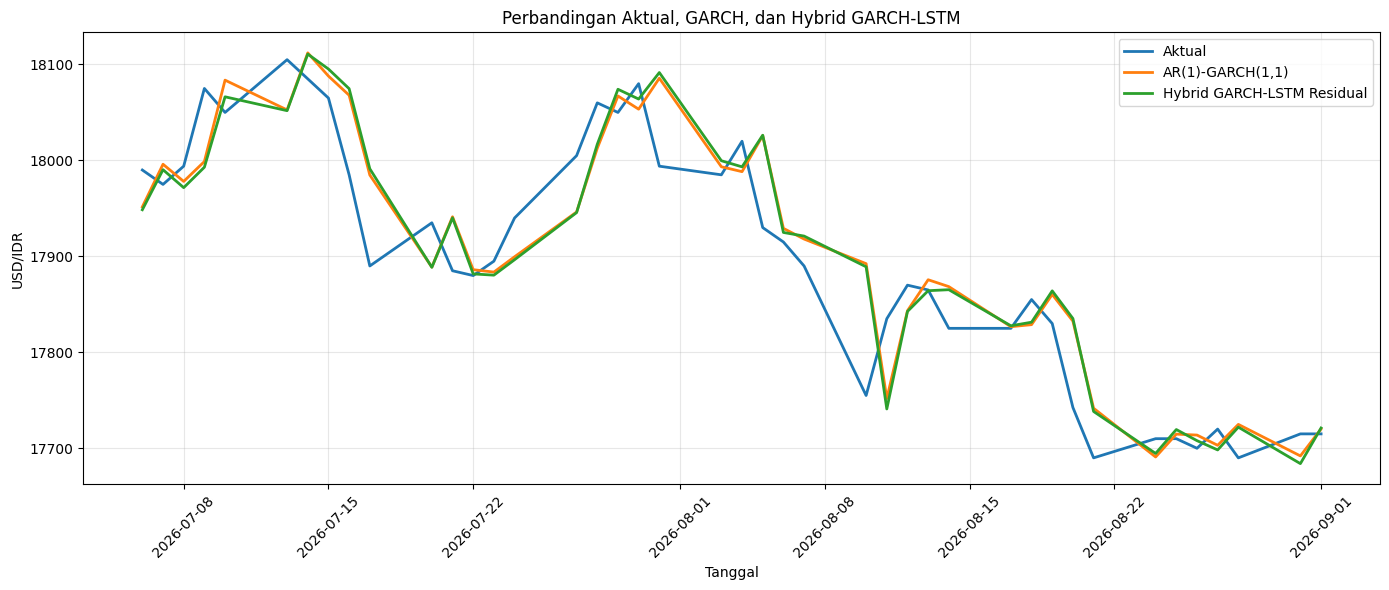

In [186]:
# ======================================
# 9. GRAFIK AKTUAL VS FORECAST HYBRID
# ======================================

if isinstance(y_test.index, pd.DatetimeIndex):
    tanggal_hybrid = y_test.index
else:
    tanggal_hybrid = data.index.take(
        y_test.index.to_numpy(dtype=int)
    )

plt.figure(figsize=(14, 6))

plt.plot(
    tanggal_hybrid,
    aktual_hybrid,
    label="Aktual",
    linewidth=2
)

plt.plot(
    tanggal_hybrid,
    forecast_garch_hybrid.to_numpy(),
    label="AR(1)-GARCH(1,1)",
    linewidth=2
)

plt.plot(
    tanggal_hybrid,
    forecast_hybrid.to_numpy(),
    label="Hybrid GARCH-LSTM Residual",
    linewidth=2
)

plt.title(
    "Perbandingan Aktual, GARCH, dan Hybrid GARCH-LSTM"
)

plt.xlabel("Tanggal")
plt.ylabel("USD/IDR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()